# A domicilio — Análisis y motor de recomendación (DHRD)

Proyecto de Datos Masivos II sobre el **Delivery Hero Recommendation Dataset**.
Se respetan sus ventanas temporales, se cuentan pedidos completos y se distinguen
el catálogo, los restaurantes activos y los casos sin historial.

1. Carga y auditoría de claves, metadata y separación temporal
2. Demanda, horarios y dispersión de la matriz usuario–restaurante
3. Repetición respecto al historial de entrenamiento y arranque en frío
4. Apriori/FP-Growth, reglas de producto por restaurante y PrefixSpan
5. PageRank, HITS binario y diagnóstico de HITS ponderado
6. Comunidades del grafo activo, con nodos aislados reportados por separado
7. Recomendación y evaluación temporal
8. Repetir, explorar y visibilidad de restaurantes con poca demanda

Los resultados se guardan en `export/resultados.json` y las figuras en `figs/`.
Las asociaciones y comunidades describen datos observados; no prueban causalidad,
disponibilidad de reparto ni preferencias independientes de la ubicación.

Para reproducir: usar **Python 3.13** con las versiones de `requirements.txt` y
ejecutar todas las celdas en orden desde la carpeta `Proyecto`. El notebook busca
`Data/DHRD` desde ese directorio o sus padres; `DHRD_DIR` permite indicar otra ruta.
Opcionalmente, `DHRD_CITY` selecciona `sg`, `se` o `tw` (predeterminado: `sg`). Las
dependencias se preparan fuera del notebook; ninguna celda instala bibliotecas.


In [1]:
import os
# Limitar hilos antes de importar NumPy/SciPy evita sobrecargar el equipo.
N_THREADS = int(os.environ.get("DHRD_THREADS", "1"))
assert N_THREADS >= 1
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                 "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = str(N_THREADS)

import json
import platform
import time
from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Image, display

CITY = os.environ.get("DHRD_CITY", "sg")
CIUDADES = {"sg": "Singapur", "se": "Estocolmo", "tw": "Taiwán"}
if CITY not in CIUDADES:
    raise ValueError(f"DHRD_CITY debe ser una de {tuple(CIUDADES)}")
CIUDAD = CIUDADES[CITY]

def resolver_datos():
    """Buscar desde proyecto/notebook; staging usa DHRD_DIR explícito."""
    valor = os.environ.get("DHRD_DIR")
    if valor:
        ruta = Path(valor).expanduser().resolve()
        if not (ruta / f"data_{CITY}").is_dir():
            raise FileNotFoundError(f"DHRD_DIR no contiene data_{CITY}: {ruta}")
        return ruta
    inicio = Path.cwd().resolve()
    for padre in (inicio, *inicio.parents):
        for ruta in (padre / "Data" / "DHRD", padre / "DHRD"):
            if (ruta / f"data_{CITY}").is_dir():
                return ruta.resolve()
    raise FileNotFoundError("No se encontró Data/DHRD. Define DHRD_DIR con su ruta.")

DATA_DIR = resolver_datos()
SMOKE = os.environ.get("DHRD_SMOKE", "0") == "1"
TOP_K = 10
SEED = 42
N_EVAL_USERS = 2_000 if SMOKE else 20_000
N_SEQ_USERS = 3_000 if SMOKE else 30_000
rng = np.random.default_rng(SEED)
OUT = Path(os.environ.get("DHRD_EXPORT_DIR", "export")); OUT.mkdir(parents=True, exist_ok=True)
FIGS = Path(os.environ.get("DHRD_FIGS_DIR", "figs")); FIGS.mkdir(parents=True, exist_ok=True)

versiones = {}
for paquete in ("numpy", "pandas", "scipy", "matplotlib", "mlxtend", "networkx"):
    try:
        versiones[paquete] = version(paquete)
    except PackageNotFoundError:
        versiones[paquete] = "no instalado"
R = {"schema_version": 2, "ciudad": CIUDAD, "city_code": CITY,
     "configuracion": {"seed": SEED, "top_k": TOP_K, "smoke": SMOKE,
                       "hilos": N_THREADS, "n_eval_users_max": N_EVAL_USERS,
                       "n_seq_users_max": N_SEQ_USERS, "data_dir": str(DATA_DIR),
                       "smoke_alcance": "Evaluación y minería de cocinas/secuencias reducidas; carga, reglas de producto y grafo completos."},
     "entorno": {"python": platform.python_version(), "paquetes": versiones},
     "generado_utc": datetime.now(timezone.utc).isoformat()}
print(f"Ciudad: {CIUDAD} ({CITY}) · modo reducido: {SMOKE} · hilos: {N_THREADS}")
print("Datos:", DATA_DIR)
if SMOKE:
    print("SMOKE reduce muestras y evaluación, pero carga datos y construye el grafo completo.")


Ciudad: Singapur (sg) · modo reducido: False · hilos: 1
Datos: /Users/mikitl/Documents/FES/Ciencia de Datos/Clases/Datos Masivos/Proyecto/Data/DHRD


## Identidad visual

Las gráficas usan la paleta del sistema de diseño **A domicilio**. La serie
categórica es jitomate → cobalto → naranja → violeta, en ese orden fijo; mostaza
y lima solo se usan como relleno con etiqueta directa, porque sobre papel no
alcanzan 3:1 de contraste.
Los títulos usan Big Shoulders Display cuando está instalada; en su ausencia usan DejaVu Sans condensada.


In [2]:
from matplotlib.font_manager import fontManager
TITLE_FONT = "Big Shoulders Display" if any(f.name == "Big Shoulders Display" for f in fontManager.ttflist) else "DejaVu Sans"
R["entorno"]["fuente_titulos"] = TITLE_FONT

JITOMATE, COBALTO, NARANJA, VIOLETA = "#dc4033", "#2e5193", "#e06129", "#5547b7"
MOSTAZA, LIMA, HOJA, BETABEL = "#f9d949", "#98c257", "#234525", "#bd2a6a"
PAPEL, KRAFT, CARBON, INK_MUTED, HAIRLINE = "#fffcdf", "#f2ede1", "#1c181a", "#5e5446", "#d9d2b8"
SERIE = [JITOMATE, COBALTO, NARANJA, VIOLETA]

plt.rcParams.update({
    "figure.facecolor": PAPEL, "axes.facecolor": PAPEL, "savefig.facecolor": PAPEL,
    "font.family": "sans-serif",
    "font.sans-serif": ["Montserrat", "DejaVu Sans", "Arial"],
    "axes.titlecolor": CARBON,
    "text.color": CARBON, "axes.labelcolor": CARBON,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.edgecolor": HAIRLINE, "axes.linewidth": 1.0,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": HAIRLINE, "grid.linewidth": 0.8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlepad": 14, "font.size": 10, "legend.frameon": False,
    "figure.dpi": 130, "savefig.bbox": "tight",
})

def guardar(fig, nombre, mostrar=True):
    """Guardar PNG para el reporte y mostrarlo también con el backend Agg."""
    ruta = FIGS / f"{nombre}.png"
    fig.savefig(ruta, dpi=200)
    print("→", ruta)
    if mostrar:
        display(Image(filename=str(ruta)))
    return ruta

def titulo_ax(ax, texto):
    """Título de gráfica: Big Shoulders Display en mayúsculas, como en el sistema."""
    ax.set_title(texto.upper(), fontfamily=TITLE_FONT, fontstretch="condensed", fontsize=16,
                 color=CARBON, loc="left", pad=14)

def miles(x):
    return f"{x:,.0f}"

def pct(x):
    return f"{x:.2f}%"

## 1. Carga y validación

Una fila de `orders` es una línea de producto; el pedido se identifica por
`order_id` dentro de una ciudad. Una oferta de producto usa la clave compuesta
`(vendor_id, product_id)`. El corte train/test original es temporal.

Se revisan campos requeridos, unicidad del catálogo, consistencia de cada pedido,
disjunción de índices/pedidos y fechas. Las líneas sin metadata de producto se
conservan y se cuentan; no se reasignan a otro restaurante. El DHRD de Singapur
incluido presenta 49 combinaciones sin catálogo (41 train y 8 test), aunque sus
IDs individuales existen. `unit_price` está normalizado: no representa moneda.


In [3]:
CITY_DIR = DATA_DIR / f"data_{CITY}"
DTYPES = {"customer_id": "category", "geohash": "category", "vendor_id": "category",
          "product_id": "category", "order_id": "int32", "day_of_week": "int8"}
t0 = time.time()
lineas_tr = pd.read_csv(CITY_DIR / f"orders_{CITY}_train.txt", index_col=0, dtype=DTYPES)
lineas_te = pd.read_csv(CITY_DIR / f"orders_{CITY}_test.txt", index_col=0, dtype=DTYPES)
vendors = pd.read_csv(CITY_DIR / f"vendors_{CITY}.txt", index_col=0,
                      dtype={"vendor_id": str, "chain_id": str, "geohash": str,
                             "primary_cuisine": str})
products = pd.read_csv(CITY_DIR / f"products_{CITY}.txt", index_col=0,
                       dtype={"vendor_id": str, "product_id": str, "name": str})
assert vendors.vendor_id.notna().all() and vendors.vendor_id.is_unique, "vendor_id duplicado/nulo en catálogo"
assert products[["vendor_id", "product_id"]].notna().all().all(), "Clave de producto nula"
assert not products.duplicated(["vendor_id", "product_id"]).any(), "Oferta de producto duplicada"
assert products.vendor_id.isin(vendors.vendor_id).all(), "Vendor de products no está en vendors"
catalogo_productos = pd.MultiIndex.from_frame(products[["vendor_id", "product_id"]])

auditoria = {}
requeridas = ["customer_id", "geohash", "order_id", "vendor_id", "product_id",
              "day_of_week", "order_time", "order_day"]
for etiqueta, df in (("train", lineas_tr), ("test", lineas_te)):
    assert df.index.is_unique, f"Índice de fila duplicado en {etiqueta}"
    assert df[requeridas].notna().all().all(), f"Campo requerido nulo en {etiqueta}"
    df["dia"] = df.order_day.str.replace(" days", "", regex=False).astype("int16")
    assert df.day_of_week.between(0, 6).all()
    assert df.order_time.str.fullmatch(r"[0-2][0-9]:[0-5][0-9]:[0-5][0-9]").all()
    df["hora"] = df.order_time.str.slice(0, 2).astype("int8")
    assert df.hora.between(0, 23).all()
    meta = ["customer_id", "vendor_id", "geohash", "dia", "day_of_week", "order_time"]
    distintas = df[["order_id", *meta]].drop_duplicates()
    conflictos = int(distintas.order_id.duplicated().sum())
    assert conflictos == 0, f"Metadata inconsistente dentro del pedido en {etiqueta}"
    sin_vendor = ~df.vendor_id.isin(vendors.vendor_id)
    sin_producto = ~df.product_id.isin(products.product_id)
    claves = pd.MultiIndex.from_frame(df[["vendor_id", "product_id"]])
    sin_oferta = ~claves.isin(catalogo_productos)
    auditoria[etiqueta] = {"lineas": int(len(df)), "dia_min": int(df.dia.min()),
        "dia_max": int(df.dia.max()), "conflictos_metadata": conflictos,
        "lineas_vendor_ausente": int(sin_vendor.sum()),
        "lineas_product_id_ausente": int(sin_producto.sum()),
        "lineas_oferta_sin_catalogo": int(sin_oferta.sum()),
        "ejemplos_oferta_sin_catalogo": df.loc[sin_oferta, ["vendor_id", "product_id"]]
            .drop_duplicates().head(5).astype(str).to_dict("records")}
    assert not sin_vendor.any(), f"Vendor desconocido en {etiqueta}"
    del distintas, claves, sin_vendor, sin_producto, sin_oferta

assert lineas_tr.index.intersection(lineas_te.index).empty, "Filas compartidas entre train/test"
assert pd.Index(lineas_tr.order_id.unique()).intersection(lineas_te.order_id.unique()).empty, "Pedido en ambos splits"
assert lineas_tr.dia.max() < lineas_te.dia.min(), "El split no es temporal"
R["auditoria_datos"] = {**auditoria,
    "indices_disjuntos": True, "pedidos_disjuntos": True, "split_temporal": True,
    "ofertas_catalogo": int(len(products)),
    "product_ids_catalogo": int(products.product_id.nunique()),
    "product_ids_repetidos_entre_vendors": int(products.product_id.duplicated().sum()),
    "chain_id_ausentes": int(vendors.chain_id.isna().sum()),
    "precios_cero": int(products.unit_price.eq(0).sum()),
    "precio_unidad": "normalizado; no moneda",
    "politica_oferta_sin_catalogo": "Conservar línea y vendor; nombre faltante explícito; no imputar desde otro vendor."}
R["carga_segundos"] = float(time.time() - t0)
print(f"Carga y auditoría en {R['carga_segundos']:.1f} s")
print("Filas (producto-pedido):", miles(len(lineas_tr)), "train ·", miles(len(lineas_te)), "test")
print("Días:", lineas_tr.dia.min(), "-", lineas_tr.dia.max(), "(train) ·",
      lineas_te.dia.min(), "-", lineas_te.dia.max(), "(test)")
print("Metadata del pedido consistente y splits disjuntos/temporales ✓")
print("Ofertas sin catálogo:", auditoria["train"]["lineas_oferta_sin_catalogo"], "train ·",
      auditoria["test"]["lineas_oferta_sin_catalogo"], "test")


Carga y auditoría en 11.9 s
Filas (producto-pedido): 3,431,870 train · 591,135 test
Días: 0 - 75 (train) · 76 - 90 (test)
Metadata del pedido consistente y splits disjuntos/temporales ✓
Ofertas sin catálogo: 41 train · 8 test


In [4]:
def a_pedidos(lineas):
    """Una fila por pedido; mantener hora completa para ordenar secuencias."""
    return (lineas.groupby("order_id", observed=True)
        .agg(customer_id=("customer_id", "first"), vendor_id=("vendor_id", "first"),
             geohash=("geohash", "first"), dia=("dia", "first"),
             dow=("day_of_week", "first"), hora=("hora", "first"),
             order_time=("order_time", "first"), n_productos=("product_id", "size"),
             n_productos_distintos=("product_id", "nunique"))
        .reset_index())

ped_tr = a_pedidos(lineas_tr)
ped_te = a_pedidos(lineas_te)
R["pedidos_multi_vendor"] = 0  # verificado para ambos splits en la celda anterior
R["pedidos_train"] = int(len(ped_tr)); R["pedidos_test"] = int(len(ped_te))
R["usuarios_train"] = int(ped_tr.customer_id.nunique())
R["usuarios_test"] = int(ped_te.customer_id.nunique())
users_tr = set(ped_tr.customer_id.astype(str)); users_te = set(ped_te.customer_id.astype(str))
R["usuarios_total"] = len(users_tr | users_te)
R["clientes_total"] = R["usuarios_total"]
R["usuarios_test_nuevos"] = len(users_te - users_tr)
R["usuarios_test_con_historial"] = len(users_te & users_tr)
R["pct_usuarios_test_nuevos"] = 100 * R["usuarios_test_nuevos"] / R["usuarios_test"]
R["vendors"] = int(vendors.vendor_id.nunique())
R["vendors_activos_train"] = int(ped_tr.vendor_id.nunique())
R["vendors_activos_test"] = int(ped_te.vendor_id.nunique())
R["vendors_sin_pedidos_train"] = R["vendors"] - R["vendors_activos_train"]
R["productos"] = int(len(products))  # ofertas distintas por vendor_id + product_id
R["product_ids_distintos_catalogo"] = int(products.product_id.nunique())
R["ofertas_producto_catalogo"] = int(len(products))
R["cocinas"] = int(vendors.primary_cuisine.nunique())
R["lineas_totales"] = int(len(lineas_tr) + len(lineas_te))
R["productos_por_pedido"] = float(ped_tr.n_productos.mean())
R["productos_distintos_por_pedido"] = float(ped_tr.n_productos_distintos.mean())
R["dias_train"] = int(ped_tr.dia.nunique()); R["dias_test"] = int(ped_te.dia.nunique())
R["denominadores"] = {"pedidos": "order_id distintos por ciudad",
    "productos_por_pedido": "líneas de producto por pedido train; no cantidad física",
    "concentracion": "restaurantes con al menos un pedido train",
    "densidad": "usuarios train × catálogo completo de restaurantes",
    "repeticion": "pedidos test de usuarios presentes en train; historial congelado al corte"}
del users_tr, users_te
pd.Series({k: R[k] for k in ["pedidos_train", "pedidos_test", "usuarios_train",
    "usuarios_test", "usuarios_total", "vendors", "vendors_activos_train", "productos", "cocinas"]})


pedidos_train            1709414
pedidos_test              290586
usuarios_train            476150
usuarios_test             171515
usuarios_total            512916
vendors                     7411
vendors_activos_train       7203
productos                1066840
cocinas                       78
dtype: int64

## 2. Exploración

Tres preguntas: ¿qué tan concentrada está la demanda?, ¿cuándo se pide?, y
¿qué tan dispersa es la matriz usuario–restaurante?

El 10% de los restaurantes activos train concentra 23.95% de los pedidos
El 20% concentra 46.68%
→ figs/01_cola_larga.png


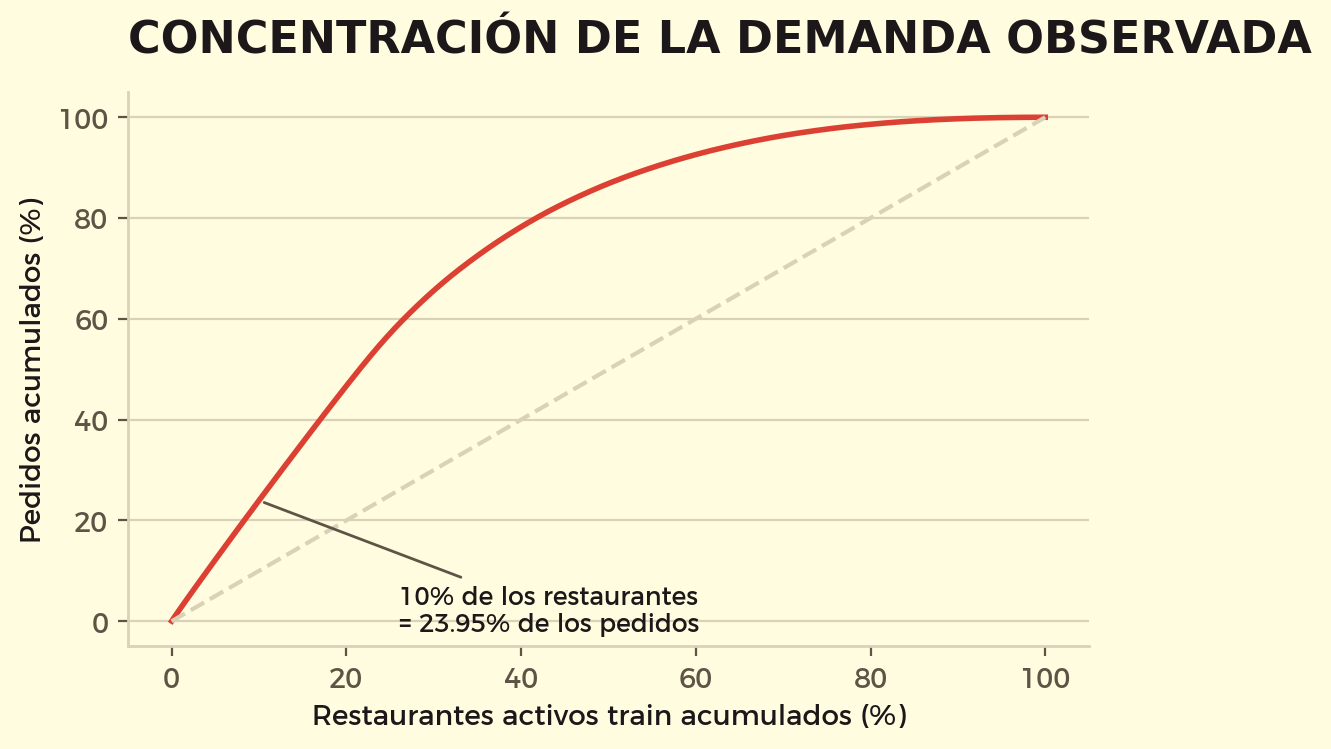

In [5]:
# --- Cola larga: qué porcentaje de pedidos concentra el top de restaurantes ---
por_vendor = ped_tr.vendor_id.astype(str).value_counts()
R["concentracion_n_vendors"] = int(len(por_vendor))
acum = por_vendor.cumsum() / por_vendor.sum()
frac_vendors = np.arange(1, len(por_vendor) + 1) / len(por_vendor)

top10 = float(acum.iloc[max(int(len(por_vendor) * 0.10) - 1, 0)] * 100)
top20 = float(acum.iloc[max(int(len(por_vendor) * 0.20) - 1, 0)] * 100)
R["concentracion_top10_vendors"] = top10
R["concentracion_top20_vendors"] = top20
print(f"El 10% de los restaurantes activos train concentra {pct(top10)} de los pedidos")
print(f"El 20% concentra {pct(top20)}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.plot(frac_vendors * 100, acum.values * 100, color=JITOMATE, lw=2)
ax.plot([0, 100], [0, 100], color=HAIRLINE, lw=1.5, ls="--")
ax.annotate(f"10% de los restaurantes\n= {pct(top10)} de los pedidos",
            xy=(10, top10), xytext=(26, top10 - 26), color=CARBON, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=INK_MUTED, lw=1))
ax.set_xlabel("Restaurantes activos train acumulados (%)"); ax.set_ylabel("Pedidos acumulados (%)")
titulo_ax(ax, "Concentración de la demanda observada")
ax.grid(axis="y"); ax.set_axisbelow(True)
guardar(fig, "01_cola_larga"); plt.close(fig)

→ figs/02_ritmo.png
→ figs/02_horarios.png
Hora pico: 18:00 (10.96%)
Mayor proporción semanal: Sáb (16.78%); mayor media por día observado: Sáb (26,071 pedidos/día)


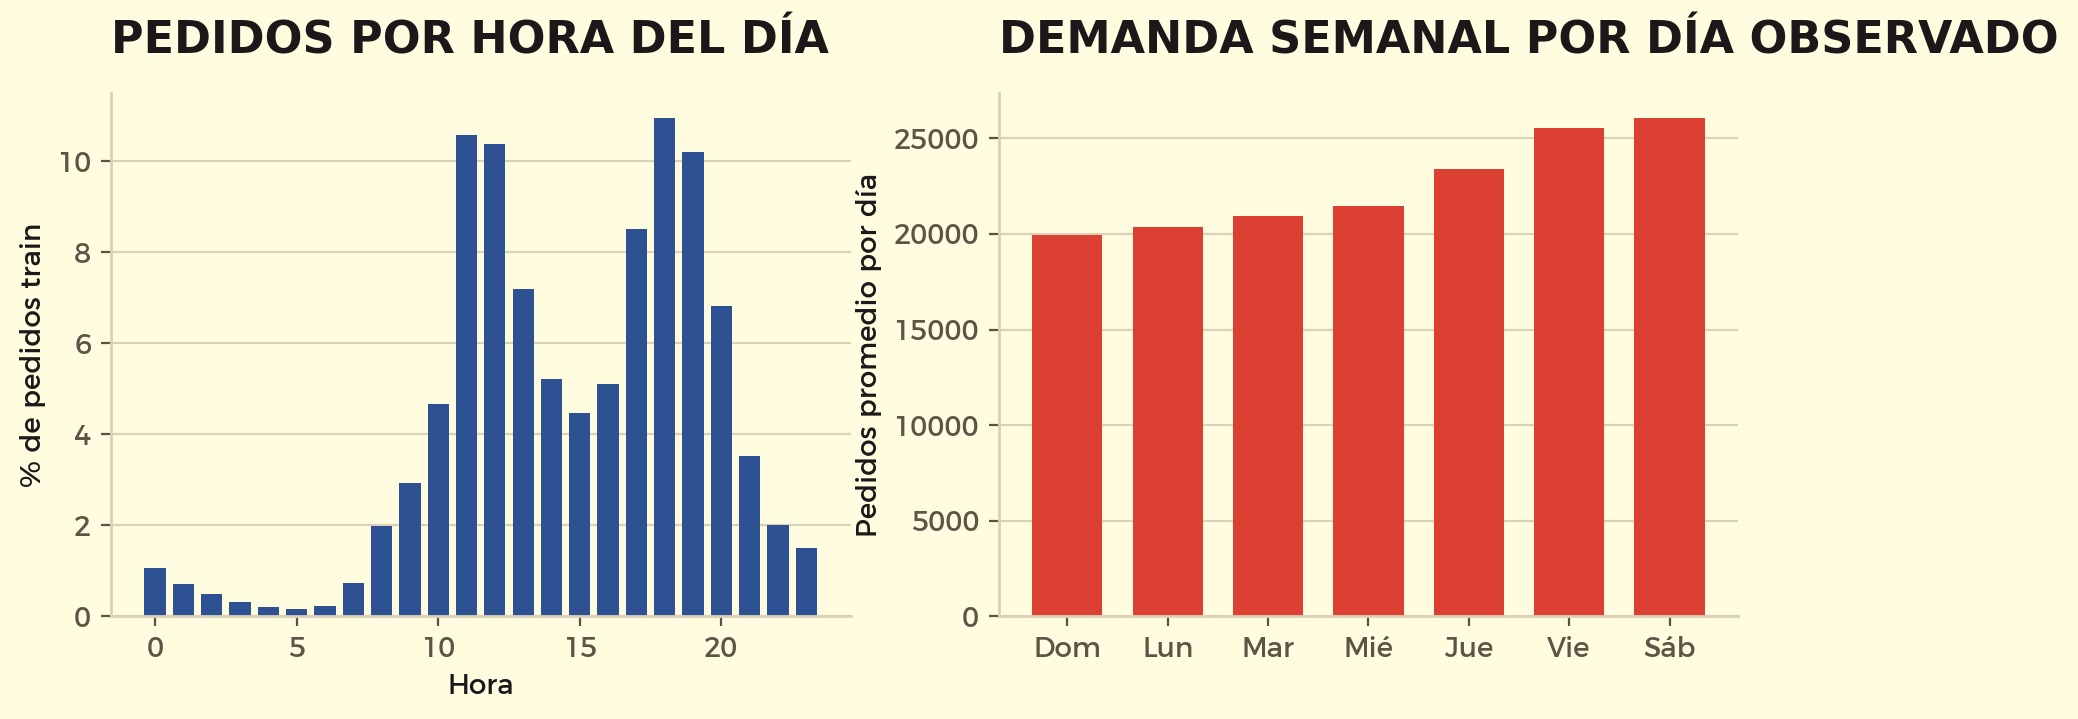

In [6]:
# --- Ritmo semanal: 0 = domingo en DHRD; ajustar por exposición ---
horas = ped_tr.hora.value_counts().sort_index()
horas_pct = horas / horas.sum() * 100
dias_nombre = ["Dom", "Lun", "Mar", "Mié", "Jue", "Vie", "Sáb"]
dow = ped_tr.dow.value_counts().reindex(range(7), fill_value=0)
dow_pct = dow / dow.sum() * 100
calendario = ped_tr[["dia", "dow"]].drop_duplicates()
assert not calendario.dia.duplicated().any(), "Un día relativo tiene varios weekdays"
n_dias_dow = calendario.dow.value_counts().reindex(range(7), fill_value=0)
dow_media = dow / n_dias_dow.replace(0, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
axes[0].bar(horas_pct.index, horas_pct.values, color=COBALTO, width=0.75)
titulo_ax(axes[0], "Pedidos por hora del día")
axes[0].set_xlabel("Hora"); axes[0].set_ylabel("% de pedidos train")
axes[1].bar(range(7), dow_media.values, color=JITOMATE, width=0.7)
axes[1].set_xticks(range(7)); axes[1].set_xticklabels(dias_nombre)
titulo_ax(axes[1], "Demanda semanal por día observado")
axes[1].set_ylabel("Pedidos promedio por día")
for ax in axes:
    ax.grid(axis="y"); ax.set_axisbelow(True)
guardar(fig, "02_ritmo")
guardar(fig, "02_horarios", mostrar=False)  # alias para el reporte
plt.close(fig)

hora_pico = int(horas_pct.idxmax())
R["hora_pico"] = hora_pico; R["hora_pico_pct"] = float(horas_pct.max())
dia_pico = int(dow_pct.idxmax())
R["dia_pico"] = dias_nombre[dia_pico]; R["dia_pico_pct"] = float(dow_pct.max())
dia_ajustado = int(dow_media.idxmax())
R["dia_pico_por_dia_observado"] = dias_nombre[dia_ajustado]
R["dia_pico_media_pedidos"] = float(dow_media.max())
R["semana"] = [{"indice_dhrd": i, "dia": dias_nombre[i], "pedidos": int(dow[i]),
    "pct_pedidos": float(dow_pct[i]), "dias_observados": int(n_dias_dow[i]),
    "pedidos_por_dia": float(dow_media[i])} for i in range(7)]
print(f"Hora pico: {hora_pico}:00 ({pct(R['hora_pico_pct'])})")
print(f"Mayor proporción semanal: {R['dia_pico']} ({pct(R['dia_pico_pct'])}); "
      f"mayor media por día observado: {R['dia_pico_por_dia_observado']} "
      f"({miles(R['dia_pico_media_pedidos'])} pedidos/día)")


In [7]:
# --- Dispersión de la matriz usuario × restaurante ---
pares = ped_tr.groupby(["customer_id", "vendor_id"], observed=True).size()
densidad = len(pares) / (R["usuarios_train"] * R["vendors"]) * 100
R["densidad_matriz"] = float(densidad)
R["pedidos_por_usuario"] = float(ped_tr.groupby("customer_id", observed=True).size().mean())
R["vendors_por_usuario"] = float(ped_tr.groupby("customer_id", observed=True)["vendor_id"]
                                 .nunique().mean())
R["pares_usuario_vendor_train"] = int(len(pares))
print(f"Densidad de la matriz (catálogo completo): {densidad:.4f}% (celdas con al menos un pedido)")
print(f"Promedio: {R['pedidos_por_usuario']:.2f} pedidos y {R['vendors_por_usuario']:.2f} restaurantes distintos por usuario")

Densidad de la matriz (catálogo completo): 0.0364% (celdas con al menos un pedido)
Promedio: 3.59 pedidos y 2.70 restaurantes distintos por usuario


## 3. Tasa de repetición

Se considera conocido un restaurante visitado **antes del corte train/test**.
El historial permanece congelado durante test. La tasa principal pondera pedidos
de usuarios con historial; también se presenta la media por usuario y la tasa
sobre todos los pedidos test. Arranque en frío por pedidos y por clientes tienen
denominadores diferentes. Estas asociaciones no implican causalidad.


Tasa de repetición: 37.06% de los pedidos test de usuarios con historial van a un restaurante ya conocido
Usuarios nuevos: 21.44% de los clientes test
Arranque en frío: 15.20% de los pedidos de prueba son de usuarios sin historial
→ figs/03_repeticion.png


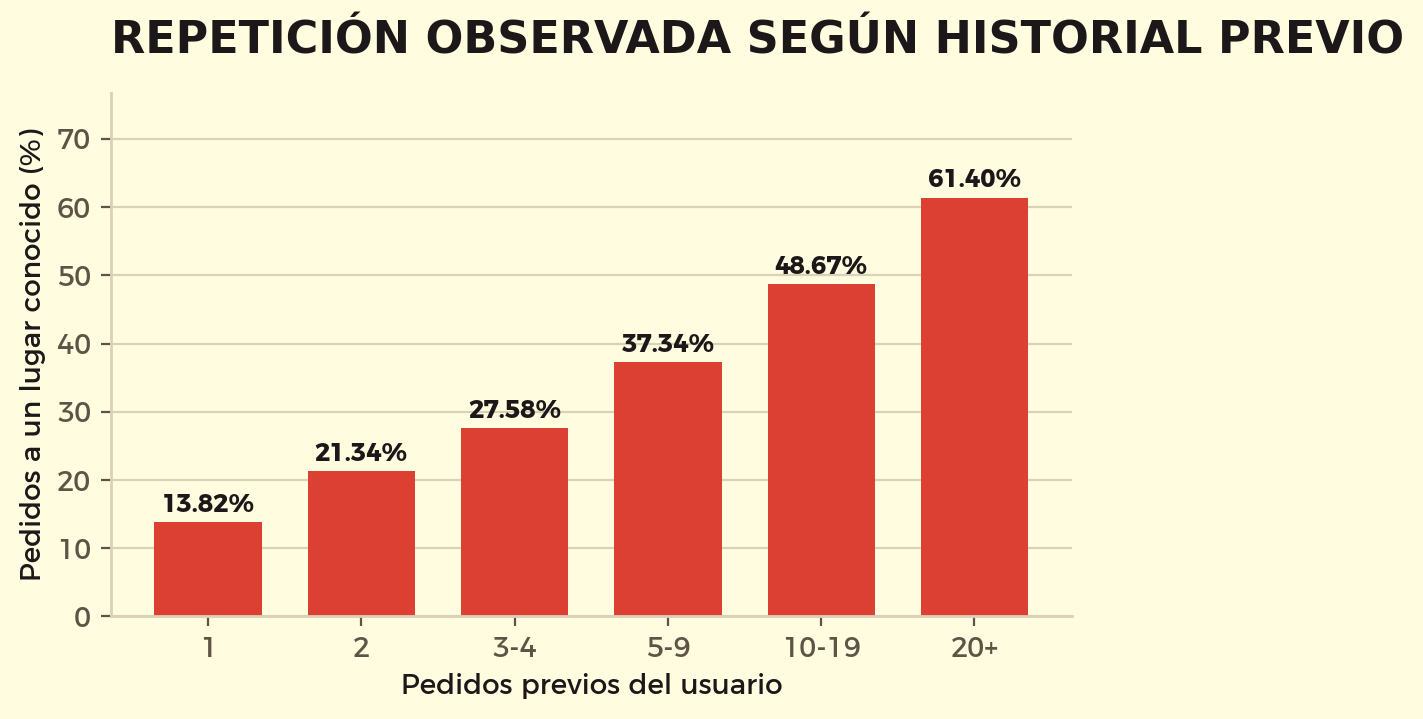

In [8]:
hist = ped_tr.groupby("customer_id", observed=True)["vendor_id"].apply(set).to_dict()
te = ped_te[["customer_id", "vendor_id", "dia", "hora", "dow", "order_id"]].copy()
te["conocido"] = [v in hist.get(c, ()) for c, v in zip(te.customer_id, te.vendor_id)]
te["usuario_nuevo"] = [c not in hist for c in te.customer_id]

conocidos = te.loc[~te.usuario_nuevo, "conocido"]
R["tasa_repeticion"] = float(conocidos.mean() * 100)
R["pedidos_test_usuarios_conocidos"] = int(len(conocidos))
R["pct_pedidos_usuario_nuevo"] = float(te.usuario_nuevo.mean() * 100)
R["pedidos_test_usuarios_nuevos"] = int(te.usuario_nuevo.sum())
R["tasa_repeticion_total"] = float(te.conocido.mean() * 100)
R["tasa_repeticion_macro_usuario"] = float(te.loc[~te.usuario_nuevo]
    .groupby("customer_id", observed=True)["conocido"].mean().mean() * 100)
print(f"Tasa de repetición: {pct(R['tasa_repeticion'])} de los pedidos test de usuarios con historial van a un restaurante ya conocido")
print(f"Usuarios nuevos: {pct(R['pct_usuarios_test_nuevos'])} de los clientes test")
print(f"Arranque en frío: {pct(R['pct_pedidos_usuario_nuevo'])} de los pedidos de prueba son de usuarios sin historial")

# Tasa de repetición por número de pedidos previos
n_prev = ped_tr.groupby("customer_id", observed=True).size()
te_c = te.loc[~te.usuario_nuevo].copy()
te_c["n_prev"] = te_c.customer_id.map(n_prev).astype(float)
cortes = [0, 1, 2, 4, 9, 19, np.inf]
etiquetas = ["1", "2", "3-4", "5-9", "10-19", "20+"]
te_c["segmento"] = pd.cut(te_c.n_prev, bins=cortes, labels=etiquetas)
rep_seg = te_c.groupby("segmento", observed=True)["conocido"].mean() * 100
R["repeticion_por_segmento"] = {str(k): float(v) for k, v in rep_seg.items()}
R["pedidos_repeticion_por_segmento"] = {str(k): int(v) for k, v in
    te_c.groupby("segmento", observed=True).size().items()}

fig, ax = plt.subplots(figsize=(6.2, 3.4))
ax.bar(range(len(rep_seg)), rep_seg.values, color=JITOMATE, width=0.7)
for i, v in enumerate(rep_seg.values):
    ax.text(i, v + 1.5, pct(v), ha="center", color=CARBON, fontsize=9, fontweight="bold")
ax.set_xticks(range(len(rep_seg))); ax.set_xticklabels(rep_seg.index)
ax.set_xlabel("Pedidos previos del usuario"); ax.set_ylabel("Pedidos a un lugar conocido (%)")
ax.set_ylim(0, min(100, rep_seg.max() * 1.25))
titulo_ax(ax, "Repetición observada según historial previo")
ax.grid(axis="y"); ax.set_axisbelow(True)
guardar(fig, "03_repeticion"); plt.close(fig)

## 4. Minería de elementos frecuentes

**Apriori y FP-Growth** usan una canasta por usuario con las cocinas observadas
en train, incluyendo usuarios de una sola cocina. En SMOKE se toma una muestra
de usuarios; el soporte usa esa población explícita. Son preferencias observadas
en un periodo, no productos de un mismo pedido.

Las reglas de producto distinguen ofertas `(vendor_id, product_id)`. Soporte y
lift principales usan **todos los pedidos train de ese restaurante**; la confianza
usa todos los pedidos con el antecedente. Los valores globales son diagnóstico:
mezclan asociación de productos con comprar en el mismo vendor. Se calculan ambas direcciones.
PrefixSpan usa una muestra de usuarios con 3–30 pedidos ordenados por día y hora;
sus patrones son subsecuencias, no necesariamente visitas consecutivas.


In [9]:
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth

cocina = vendors.set_index("vendor_id")["primary_cuisine"]
ped_tr["cocina"] = ped_tr.vendor_id.astype(str).map(cocina).astype("category")
ped_te["cocina"] = ped_te.vendor_id.astype(str).map(cocina).astype("category")
canastas = (ped_tr.loc[ped_tr.cocina.notna()]
    .groupby(["customer_id", "cocina"], observed=True).size().unstack(fill_value=0) > 0)
n_canastas_poblacion = len(canastas)
if SMOKE:
    canastas = canastas.sample(min(len(canastas), 50_000), random_state=SEED)
R["canastas_n"] = int(len(canastas))
R["n_canastas_cocina"] = R["canastas_n"]
R["canastas_usuarios_elegibles"] = int(n_canastas_poblacion)
R["canastas_cocinas"] = int(canastas.shape[1])
R["canastas_poblacion"] = "usuarios con al menos una cocina identificada en train; una canasta por usuario"
R["canastas_muestra"] = bool(len(canastas) < n_canastas_poblacion)
print("Canastas:", miles(len(canastas)), "usuarios ×", canastas.shape[1], "cocinas; incluye una sola cocina")

MIN_SUP = 0.02
tiempos = {"fp": [], "ap": []}
# Alternar el orden y reportar mediana; comparación local, no prueba de escalado.
for repeticion in range(3):
    orden = ("fp", "ap") if repeticion % 2 == 0 else ("ap", "fp")
    for algoritmo in orden:
        inicio = time.perf_counter()
        if algoritmo == "fp":
            frec_fp = fpgrowth(canastas, min_support=MIN_SUP, use_colnames=True)
        else:
            frec_ap = apriori(canastas, min_support=MIN_SUP, use_colnames=True)
        tiempos[algoritmo].append(time.perf_counter() - inicio)
sup_fp = dict(zip(frec_fp.itemsets, frec_fp.support))
sup_ap = dict(zip(frec_ap.itemsets, frec_ap.support))
assert sup_fp.keys() == sup_ap.keys(), "Apriori y FP-Growth produjeron distintos itemsets"
assert all(np.isclose(sup_fp[k], sup_ap[k]) for k in sup_fp), "Soportes inconsistentes"
R["fpgrowth_segundos"] = float(np.median(tiempos["fp"]))
R["apriori_segundos"] = float(np.median(tiempos["ap"]))
R["benchmark_itemsets"] = {"repeticiones": 3, "estadistico": "mediana",
    "fpgrowth_segundos": tiempos["fp"], "apriori_segundos": tiempos["ap"],
    "resultados_equivalentes": True, "soporte_minimo": MIN_SUP}
R["itemsets_frecuentes"] = int(len(frec_fp))
print(f"Medianas locales: FP-Growth {R['fpgrowth_segundos']:.2f} s · "
      f"Apriori {R['apriori_segundos']:.2f} s · {len(frec_fp)} itemsets, soporte ≥ {MIN_SUP:.0%}")
reglas = association_rules(frec_fp, num_itemsets=len(canastas), metric="lift", min_threshold=1.2)
reglas = reglas.sort_values("lift", ascending=False)
reglas["antecedente"] = reglas.antecedents.apply(lambda s: ", ".join(sorted(s)))
reglas["consecuente"] = reglas.consequents.apply(lambda s: ", ".join(sorted(s)))
top_reglas = reglas[["antecedente", "consecuente", "support", "confidence", "lift"]].head(10)
R["reglas_cocina"] = [
    {"antecedente": a, "consecuente": c, "soporte": float(s) * 100,
     "confianza": float(cf) * 100, "lift": float(l), "usuarios_denominador": len(canastas)}
    for a, c, s, cf, l in top_reglas.itertuples(index=False, name=None)]
top_reglas


Canastas: 476,150 usuarios × 78 cocinas; incluye una sola cocina
Medianas locales: FP-Growth 5.11 s · Apriori 1.13 s · 39 itemsets, soporte ≥ 2%

,antecedente,consecuente,support,confidence,lift
2,chinese,noodles,0.033983,0.194310,1.869411
3,noodles,chinese,0.033983,0.326942,1.869411
5,japanese,chinese,0.025187,0.295547,1.689899
4,chinese,japanese,0.025187,0.144019,1.689899
8,chinese,coffee,0.023226,0.132803,1.427951
9,coffee,chinese,0.023226,0.249735,1.427951
6,chinese,western,0.021691,0.124024,1.291338
7,western,chinese,0.021691,0.225842,1.291338
0,chinese,dessert,0.021628,0.123664,1.254584
1,dessert,chinese,0.021628,0.219414,1.254584


In [10]:
# --- Reglas de oferta: todos los pedidos del vendor, ambas direcciones ---
ord_codes, ord_uniq = pd.factorize(lineas_tr.order_id)
claves_producto = pd.MultiIndex.from_frame(lineas_tr[["vendor_id", "product_id"]])
prod_codes, prod_uniq = pd.factorize(claves_producto)
A = sp.csr_matrix((np.ones(len(lineas_tr), dtype=np.float32), (ord_codes, prod_codes)),
                  shape=(len(ord_uniq), len(prod_uniq)))
A.sum_duplicates(); A.data[:] = 1.0  # presencia, aunque una oferta tenga varias líneas
co = sp.triu(A.T @ A, k=1).tocoo()
conteo_prod = np.asarray(A.sum(axis=0)).ravel()
n_ped_reglas = A.shape[0]
MIN_PARES = 5 if SMOKE else 30
mask = co.data >= MIN_PARES
pares_base = pd.DataFrame({"ia": co.row[mask], "ib": co.col[mask], "juntos": co.data[mask]})
inversos = pares_base.rename(columns={"ia": "ib", "ib": "ia"})
pares_df = pd.concat([pares_base, inversos], ignore_index=True)
ia = pares_df.ia.to_numpy(); ib = pares_df.ib.to_numpy()
catalogo_nombres = products.set_index(["vendor_id", "product_id"])["name"]
meta_prod = prod_uniq.to_frame(index=False)
meta_prod.columns = ["vendor_id", "product_id"]
meta_prod["name"] = catalogo_nombres.reindex(prod_uniq).fillna("Sin nombre en catálogo").to_numpy()
pares_df["vendor_id"] = meta_prod.vendor_id.to_numpy()[ia]
assert np.array_equal(meta_prod.vendor_id.to_numpy()[ia], meta_prod.vendor_id.to_numpy()[ib]), "Par de distintos vendors"
pares_df["a"] = meta_prod.product_id.to_numpy()[ia]
pares_df["b"] = meta_prod.product_id.to_numpy()[ib]
pares_df["producto A"] = meta_prod.name.to_numpy()[ia]
pares_df["producto B"] = meta_prod.name.to_numpy()[ib]
pares_df["pedidos_con_A"] = conteo_prod[ia]
pares_df["pedidos_con_B"] = conteo_prod[ib]
pedidos_por_vendor = ped_tr.vendor_id.astype(str).value_counts()
pares_df["pedidos_vendor"] = pares_df.vendor_id.map(pedidos_por_vendor).astype("int32")
pares_df["soporte_global"] = pares_df.juntos.astype(float) / n_ped_reglas * 100
pares_df["lift_global"] = pares_df.juntos.astype(float) * n_ped_reglas / (conteo_prod[ia].astype(float) * conteo_prod[ib])
pares_df["soporte_vendor"] = pares_df.juntos.astype(float) / pares_df.pedidos_vendor * 100
pares_df["lift_vendor"] = pares_df.juntos.astype(float) * pares_df.pedidos_vendor / (conteo_prod[ia].astype(float) * conteo_prod[ib])
pares_df["soporte"] = pares_df.soporte_vendor  # alias principal para el reporte
pares_df["confianza"] = pares_df.juntos / conteo_prod[ia] * 100
pares_df["lift"] = pares_df.lift_vendor
top_pares = pares_df.sort_values(["juntos", "confianza"], ascending=False).head(10)
R["reglas_producto_metadatos"] = {"pedidos_globales_matriz": int(n_ped_reglas),
    "ofertas_observadas": int(len(prod_uniq)), "min_pedidos_conjuntos": MIN_PARES,
    "pares_no_dirigidos": int(len(pares_base)), "reglas_dirigidas": int(len(pares_df)),
    "clave_oferta": "ciudad, vendor_id, product_id", "matriz_binaria": True,
    "soporte_universo": "todos los pedidos train del vendor de A y B", "direccion": "ambas",
    "confianza_definicion": "pedidos con A y B / todos los pedidos con A",
    "lift_definicion": "coocurrencia × pedidos del vendor / (pedidos con A × pedidos con B)",
    "diagnostico_global": "soporte_global y lift_global usan pedidos de toda la ciudad; el lift global mezcla asociación con vendor compartido y no mide complementariedad dentro del menú."}
R["pares_producto"] = [
    {"a": str(r["producto A"]), "b": str(r["producto B"]), "vendor_id": str(r.vendor_id),
     "product_id_a": str(r.a), "product_id_b": str(r.b), "juntos": int(r.juntos),
     "pedidos_con_a": int(r.pedidos_con_A), "pedidos_con_b": int(r.pedidos_con_B),
     "pedidos_vendor": int(r.pedidos_vendor), "soporte": float(r.soporte),
     "soporte_vendor": float(r.soporte_vendor), "confianza": float(r.confianza),
     "lift": float(r.lift), "lift_vendor": float(r.lift_vendor),
     "soporte_global": float(r.soporte_global), "lift_global": float(r.lift_global)}
    for _, r in top_pares.iterrows()]
print("Reglas dirigidas: soporte y lift condicionados al vendor; confianza sobre todos los pedidos con A.")
print("Lift global se conserva solo como diagnóstico de asociación con vendor compartido.")
display(top_pares[["vendor_id", "producto A", "producto B", "juntos", "pedidos_vendor", "soporte_vendor", "confianza", "lift_vendor"]])
# La multiplicación dispersa puede crecer con canastas grandes; el umbral se aplica después.
del claves_producto, ord_codes, prod_codes, co, mask, inversos, meta_prod, catalogo_nombres

R["pedidos_producto_canastas"] = int(n_ped_reglas)  # todos los pedidos train


Reglas dirigidas: soporte y lift condicionados al vendor; confianza sobre todos los pedidos con A.
Lift global se conserva solo como diagnóstico de asociación con vendor compartido.


,vendor_id,producto A,producto B,juntos,pedidos_vendor,soporte_vendor,confianza,lift_vendor
3978,a4216d5d,Claypot Bak Kut Teh 阿嬷肉骨茶,Rice 白饭,293.0,530,55.283019,82.072830,1.076698
12509,a4216d5d,Rice 白饭,Claypot Bak Kut Teh 阿嬷肉骨茶,293.0,530,55.283019,72.524750,1.076698
11415,89b99b42,Claypot Bak Kut Teh Original,Rice,261.0,554,47.111913,75.000000,1.036160
2884,89b99b42,Rice,Claypot Bak Kut Teh Original,261.0,554,47.111913,65.087280,1.036160
11854,a1f9f94d,Black Rojak,Youtiao Rojak,236.0,555,42.522523,63.783783,0.896203
3323,a1f9f94d,Youtiao Rojak,Black Rojak,236.0,555,42.522523,59.746838,0.896203
8608,83e5a508,Regular,White Rice 白饭,232.0,540,42.962963,78.911568,1.029281
77,83e5a508,White Rice 白饭,Regular,232.0,540,42.962963,56.038647,1.029281
1691,6c057f95,C1s. Pork Ribs Soup,A1s. Fragrant White Rice,210.0,356,58.988764,82.677170,0.997731
1142,f713fd78,6. Sesame Chicken 砂锅麻油宫保鸡丁,Plain Rice,210.0,545,38.532110,77.777779,1.011668


In [11]:
# --- PrefixSpan sobre la secuencia de cocinas de cada usuario ---
def prefixspan(secuencias, min_sup, max_len=3):
    """PrefixSpan clásico sobre secuencias de símbolos (items simples)."""
    resultados = []

    def recurre(prefijo, proyectada):
        # conteo de símbolos que pueden extender el prefijo
        conteo = {}
        for idx, pos in proyectada:
            vistos = set()
            for s in secuencias[idx][pos:]:
                if s not in vistos:
                    vistos.add(s)
                    conteo[s] = conteo.get(s, 0) + 1
        for simbolo, c in conteo.items():
            if c < min_sup:
                continue
            nuevo = prefijo + [simbolo]
            resultados.append((tuple(nuevo), c))
            if len(nuevo) < max_len:
                nueva_proj = []
                for idx, pos in proyectada:
                    seq = secuencias[idx]
                    for j in range(pos, len(seq)):
                        if seq[j] == simbolo:
                            nueva_proj.append((idx, j + 1))
                            break
                recurre(nuevo, nueva_proj)

    recurre([], [(i, 0) for i in range(len(secuencias))])
    return resultados

seq_src = ped_tr.loc[ped_tr.cocina.notna(), ["customer_id", "dia", "order_time", "order_id", "cocina"]]
seq_src = seq_src.sort_values(["customer_id", "dia", "order_time", "order_id"])
tam = seq_src.groupby("customer_id", observed=True).size()
elegibles = tam[tam.between(3, 30)].index
n_elegibles_secuencia = len(elegibles)
elegibles = pd.Index(np.random.default_rng(SEED + 17).choice(np.asarray(elegibles), size=min(N_SEQ_USERS, len(elegibles)),
                                replace=False))
sub = seq_src[seq_src.customer_id.isin(elegibles)]
secuencias = [list(g) for _, g in sub.groupby("customer_id", observed=True)["cocina"]]
print("Secuencias:", miles(len(secuencias)), "· largo medio:", f"{np.mean([len(s) for s in secuencias]):.1f}")

assert len(secuencias) > 0, "No hay usuarios elegibles para secuencias"
min_sup = max(1, int(np.ceil(0.02 * len(secuencias))))
R["secuencias_n"] = int(len(secuencias))
R["secuencias_metadatos"] = {"usuarios_elegibles": int(n_elegibles_secuencia),
    "usuarios_muestra": len(secuencias), "pedidos_min": 3, "pedidos_max": 30,
    "largo_medio": float(np.mean([len(s) for s in secuencias])),
    "patron_largo_maximo": 3, "soporte_minimo_secuencias": min_sup,
    "orden": "cliente, día, order_time completo, order_id",
    "tipo": "subsecuencias; no necesariamente consecutivas", "seed": SEED + 17}
t0 = time.time()
patrones = prefixspan(secuencias, min_sup=min_sup, max_len=3)
R["prefixspan_segundos"] = float(time.time() - t0)
print(f"PrefixSpan en {R['prefixspan_segundos']:.1f} s · {len(patrones)} patrones con soporte ≥ 2%")

pat_df = pd.DataFrame([{"patrón": " → ".join(p), "largo": len(p),
                        "soporte": c / len(secuencias) * 100} for p, c in patrones])
top_sec = pat_df[pat_df.largo >= 2].sort_values("soporte", ascending=False).head(10)
R["patrones_secuencia"] = [{"patron": r["patrón"], "soporte": float(r.soporte)}
                           for _, r in top_sec.iterrows()]
top_sec

Secuencias: 30,000 · largo medio: 6.6
PrefixSpan en 0.4 s · 128 patrones con soporte ≥ 2%

,patrón,largo,soporte
6,chinese → chinese,2,13.853333
93,indian → indian,2,8.486667
8,chinese → chinese → chinese,3,7.240000
40,noodles → noodles,2,7.210000
85,bubble tea → bubble tea,2,6.516667
71,coffee → coffee,2,6.063333
4,chinese → noodles,2,5.473333
37,noodles → chinese,2,5.473333
59,dessert → dessert,2,5.203333
23,japanese → japanese,2,5.136667


## 5. Análisis de vínculos

`M` cuenta pedidos por usuario–restaurante. `B` representa presencia binaria.
El grafo proyectado conecta restaurantes mediante **clientes únicos compartidos**,
sin diagonal y con al menos dos clientes por arista. Se aplica PageRank con método
de potencias y manejo de nodos sin grado. HITS principal utiliza `B`; el ponderado
con `M` se conserva como diagnóstico de sensibilidad a clientes repetitivos.
La correlación con pedidos permite examinar cuánto agrega la centralidad a la popularidad.


In [12]:
usuarios = pd.Index(ped_tr.customer_id.astype(str).unique())
vendor_idx = pd.Index(vendors.vendor_id.astype(str).unique())
u_pos = pd.Series(np.arange(len(usuarios)), index=usuarios)
v_pos = pd.Series(np.arange(len(vendor_idx)), index=vendor_idx)

ui = ped_tr.customer_id.astype(str).map(u_pos).to_numpy()
vi = ped_tr.vendor_id.astype(str).map(v_pos).to_numpy()
ok = ~np.isnan(vi)
ui, vi = ui[ok].astype(np.int32), vi[ok].astype(np.int32)

M = sp.csr_matrix((np.ones(len(ui), dtype=np.float32), (ui, vi)),
                  shape=(len(usuarios), len(vendor_idx)))
M.sum_duplicates()
M_csr = M.tocsr()
print("Matriz usuario × restaurante:", M.shape, "·", miles(M.nnz), "celdas ocupadas")

# Proyección restaurante–restaurante (clientes compartidos), sin la diagonal
B = M.copy(); B.data[:] = 1.0
S = (B.T @ B).tocsr()
S.setdiag(0); S.eliminate_zeros()
MIN_CLIENTES_COMPARTIDOS = 2      # une dos restaurantes solo si comparten 2+ clientes
S.data[S.data < MIN_CLIENTES_COMPARTIDOS] = 0
S.eliminate_zeros()
print("Grafo de restaurantes:", S.shape[0], "nodos ·", miles(S.nnz // 2), "aristas",
      f"(≥ {MIN_CLIENTES_COMPARTIDOS} clientes compartidos)")
cocina_v = pd.Series(vendor_idx).map(vendors.set_index("vendor_id")["primary_cuisine"]).values
R["grafo_metadatos"] = {"usuarios": int(M.shape[0]), "vendors_catalogo": int(M.shape[1]),
    "interacciones_usuario_vendor": int(M.nnz), "aristas": int(S.nnz // 2),
    "min_clientes_compartidos": MIN_CLIENTES_COMPARTIDOS,
    "nodos_con_aristas": int(np.count_nonzero(np.diff(S.indptr))),
    "nodos_aislados": int(np.count_nonzero(np.diff(S.indptr) == 0)),
    "peso_arista": "clientes únicos compartidos; no número de pedidos"}

R["min_clientes_compartidos"] = MIN_CLIENTES_COMPARTIDOS
R["n_nodos_aislados"] = R["grafo_metadatos"]["nodos_aislados"]


Matriz usuario × restaurante: (476150, 7411) · 1,285,976 celdas ocupadas
Grafo de restaurantes: 7411 nodos · 498,014 aristas (≥ 2 clientes compartidos)


In [13]:
def normaliza_columnas(X):
    """Matriz de transición columna-estocástica."""
    X = X.astype(np.float64)
    grados = np.asarray(X.sum(axis=0)).ravel()
    inv = np.zeros_like(grados); nz = grados > 0
    inv[nz] = 1.0 / grados[nz]
    return X @ sp.diags(inv), nz

def pagerank_potencias(X, d=0.85, tol=1e-10, max_iter=200):
    """PageRank por el método de potencias (tema 1.1 aplicado al 3.1)."""
    n = X.shape[0]
    assert n > 0 and X.shape == (n, n) and 0 < d < 1
    P, tiene_grado = normaliza_columnas(X)
    r = np.full(n, 1.0 / n)
    sin_grado = ~tiene_grado
    for it in range(max_iter):
        nuevo = d * (P @ r) + d * r[sin_grado].sum() / n + (1 - d) / n
        delta = np.abs(nuevo - r).sum()
        r = nuevo
        if delta < tol:
            break
    if delta >= tol:
        raise RuntimeError(f"PageRank no convergió: delta={delta:.3g}")
    return r, it + 1, delta

t0 = time.time()
pr, iters, delta = pagerank_potencias(S)
assert np.isclose(pr.sum(), 1.0) and np.all(pr >= 0)
R["pagerank_iteraciones"] = int(iters)
R["pagerank_delta"] = float(delta)
R["pagerank_convergencia"] = True
R["pagerank_segundos"] = float(time.time() - t0)
print(f"PageRank convergió en {iters} iteraciones ({R['pagerank_segundos']:.1f} s, delta={delta:.2e})")

pop = np.asarray(M.sum(axis=0)).ravel()
tabla_pr = pd.DataFrame({
    "vendor_id": vendor_idx, "pagerank": pr, "pedidos": pop,
    "cocina": pd.Series(vendor_idx).map(vendors.set_index("vendor_id")["primary_cuisine"]).values,
}).sort_values("pagerank", ascending=False)
R["top_pagerank"] = [{"vendor": r.vendor_id, "cocina": str(r.cocina), "pedidos": int(r.pedidos)}
                     for _, r in tabla_pr.head(10).iterrows()]

# Correlación entre centralidad y popularidad: ¿PageRank dice algo nuevo?
from scipy.stats import spearmanr
rho = spearmanr(pr, pop).statistic
R["correlacion_pagerank_popularidad"] = float(rho)
print(f"Correlación de Spearman entre PageRank y número de pedidos: {rho:.3f}")
tabla_pr.head(10)

PageRank convergió en 95 iteraciones (0.1 s, delta=8.32e-11)
Correlación de Spearman entre PageRank y número de pedidos: 0.957

,vendor_id,pagerank,pedidos,cocina
5142,f3024b8e,0.000725,571.0,dim sum
5507,e35a8c91,0.000691,559.0,japanese
578,89e1250f,0.000681,543.0,thai
6909,22c887de,0.000679,540.0,singaporean
5211,930068e0,0.000670,594.0,japanese
5166,0033029f,0.000665,560.0,dim sum
3309,53fb28d4,0.000645,548.0,chinese
5439,7f528535,0.000626,574.0,japanese
5342,1bd969b8,0.000625,529.0,japanese
495,e13dc36b,0.000625,573.0,porridge


In [14]:
# --- HITS principal binario; frecuencia de pedidos como diagnóstico ---
def hits(X, max_iter=2000, tol=1e-8, return_info=False):
    """Vectores singulares dominantes; norma L2 y residual explícito."""
    a = np.ones(X.shape[1]) / np.sqrt(X.shape[1])
    delta = np.inf
    for it in range(max_iter):
        h = X @ a; h /= np.linalg.norm(h) or 1
        nuevo = X.T @ h; nuevo /= np.linalg.norm(nuevo) or 1
        delta = float(np.abs(nuevo - a).sum())
        a = nuevo
        if delta < tol:
            break
    h = X @ a; h /= np.linalg.norm(h) or 1
    info = {"iteraciones": it + 1, "delta": delta, "convergio": bool(delta < tol),
            "tol": tol, "max_iter": max_iter}
    return (h, a, info) if return_info else (h, a)

inicio = time.perf_counter()
hubs, autoridades, info_hits = hits(B, return_info=True)
info_hits["segundos"] = float(time.perf_counter() - inicio)
inicio = time.perf_counter()
hubs_ponderados, autoridades_ponderadas, info_hits_ponderado = hits(M, return_info=True)
info_hits_ponderado["segundos"] = float(time.perf_counter() - inicio)
tabla_hits = pd.DataFrame({"vendor_id": vendor_idx, "autoridad": autoridades,
    "pedidos": pop, "clientes": np.asarray(B.sum(axis=0)).ravel(), "cocina": cocina_v})
tabla_hits = tabla_hits.sort_values("autoridad", ascending=False)
tabla_hits_ponderado = pd.DataFrame({"vendor_id": vendor_idx, "autoridad": autoridades_ponderadas,
    "pedidos": pop, "cocina": cocina_v}).sort_values("autoridad", ascending=False)
R["top_autoridades"] = [{"vendor": r.vendor_id, "cocina": str(r.cocina),
    "pedidos": int(r.pedidos), "clientes": int(r.clientes), "autoridad": float(r.autoridad)}
    for _, r in tabla_hits.head(10).iterrows()]
R["top_autoridades_ponderadas"] = [{"vendor": r.vendor_id, "cocina": str(r.cocina),
    "pedidos": int(r.pedidos), "autoridad": float(r.autoridad)}
    for _, r in tabla_hits_ponderado.head(10).iterrows()]
R["correlacion_hits_popularidad"] = float(spearmanr(autoridades, pop).statistic)
R["correlacion_hits_ponderado_popularidad"] = float(spearmanr(autoridades_ponderadas, pop).statistic)
v_top_peso = int(np.argmax(autoridades_ponderadas))
columna_peso = M_csr[:, v_top_peso].toarray().ravel()
R["hits_metadatos"] = {"principal": "binario: una interacción por usuario/vendor",
    "binario": info_hits, "ponderado": info_hits_ponderado,
    "autoridad_max_binario": float(autoridades.max()),
    "autoridad_max_ponderado": float(autoridades_ponderadas.max()),
    "masa_cuadratica_max_ponderado_pct": float(autoridades_ponderadas.max() ** 2 * 100),
    "vendor_max_ponderado": str(vendor_idx[v_top_peso]),
    "pedidos_vendor_max_ponderado": int(columna_peso.sum()),
    "clientes_vendor_max_ponderado": int(np.count_nonzero(columna_peso)),
    "pedidos_cliente_max_en_vendor_ponderado": int(columna_peso.max())}
del columna_peso
print(f"HITS binario: convergencia={info_hits['convergio']}, "
      f"autoridad–pedidos rho={R['correlacion_hits_popularidad']:.3f}")
print(f"Diagnóstico ponderado: autoridad máxima={autoridades_ponderadas.max():.6f}, "
      f"masa cuadrática={R['hits_metadatos']['masa_cuadratica_max_ponderado_pct']:.2f}%")
R["hits_diagnostico"] = R["hits_metadatos"]
tabla_hits.head(10)


HITS binario: convergencia=True, autoridad–pedidos rho=0.928
Diagnóstico ponderado: autoridad máxima=0.998588, masa cuadrática=99.72%

,vendor_id,autoridad,pedidos,clientes,cocina
5157,89e35c84,0.060619,632.0,490.0,dim sum
721,8ca2e257,0.058618,547.0,481.0,asian
4458,1ef9084e,0.058348,530.0,381.0,noodles
1605,e408e5c0,0.057561,608.0,463.0,sushi
5512,8a0e1ff2,0.056942,540.0,447.0,beverages
6860,6604079e,0.056781,542.0,381.0,singaporean
736,49de578b,0.056720,565.0,430.0,asian
2048,8a54a8c1,0.056633,530.0,446.0,coffee
3074,200155f3,0.056568,560.0,461.0,chinese
3540,33e10dfe,0.056329,574.0,385.0,chinese


## 6. Comunidades del grafo activo

Louvain se aplica a restaurantes que tienen aristas de clientes compartidos.
Los nodos aislados se cuentan aparte y no reciben una comunidad de gusto.
Se conserva la unión de las quince aristas más fuertes elegidas por cada nodo:
el grado final puede superar quince. La modularidad describe **este grafo podado**.
Las comunidades pueden reflejar tanto ubicación y acceso como preferencias.


In [15]:
import networkx as nx

K_VECINOS = 15
filas, cols, pesos = [], [], []
S_lil = S.tocsr()
activos_grafo = np.flatnonzero(np.diff(S_lil.indptr) > 0)
aislados_grafo = np.flatnonzero(np.diff(S_lil.indptr) == 0)
for i in activos_grafo:
    ini, fin = S_lil.indptr[i], S_lil.indptr[i + 1]
    vecinos = S_lil.indices[ini:fin]; w = S_lil.data[ini:fin]
    sel = np.lexsort((vecinos, -w))[:K_VECINOS]  # desempate reproducible
    filas.append(np.full(len(sel), i)); cols.append(vecinos[sel]); pesos.append(w[sel])
ii = np.concatenate(filas) if filas else np.array([], dtype=int)
jj = np.concatenate(cols) if cols else np.array([], dtype=int)
ww = np.concatenate(pesos) if pesos else np.array([], dtype=float)
lo, hi = np.minimum(ii, jj), np.maximum(ii, jj)
aristas = pd.DataFrame({"i": lo, "j": hi, "w": ww}).drop_duplicates(["i", "j"])
G = nx.Graph()
G.add_nodes_from(activos_grafo.tolist())
G.add_weighted_edges_from(aristas[["i", "j", "w"]].itertuples(index=False, name=None))
inicio = time.perf_counter()
comunidades = nx.community.louvain_communities(G, weight="weight", seed=SEED) if G.number_of_edges() else []
comunidades = sorted(comunidades, key=lambda c: (-len(c), min(c)))
R["louvain_segundos"] = float(time.perf_counter() - inicio)
com_de = np.full(len(vendor_idx), -1)
for c, nodos in enumerate(comunidades):
    com_de[list(nodos)] = c
R["n_comunidades"] = len(comunidades)
R["modularidad"] = float(nx.community.modularity(G, comunidades, weight="weight")) if comunidades else 0.0
R["comunidades_metadatos"] = {"nodos_activos": int(len(activos_grafo)),
    "nodos_aislados": int(len(aislados_grafo)),
    "aislados_sin_pedidos_train": int(np.count_nonzero(pop[aislados_grafo] == 0)),
    "aislados_con_pedidos_train": int(np.count_nonzero(pop[aislados_grafo] > 0)),
    "aristas_grafo_podado": int(G.number_of_edges()), "k_vecinos_seleccionados": K_VECINOS,
    "poda": "unión de selecciones por nodo; grado final no acotado a K",
    "modularidad_universo": "grafo activo podado; excluye aislados", "seed": SEED}
print(f"Louvain: {len(comunidades)} comunidades activas · {len(aislados_grafo)} aislados aparte "
      f"· modularidad {R['modularidad']:.3f} · {R['louvain_segundos']:.1f} s")
resumen_com = []
for c, nodos in enumerate(comunidades[:6]):
    idx = np.array(sorted(nodos), dtype=int)
    cocinas_c = pd.Series(cocina_v[idx]).value_counts().head(3)
    zonas = vendors.set_index("vendor_id").reindex(vendor_idx[idx]).geohash.value_counts().head(2)
    resumen_com.append({"comunidad": c, "restaurantes": int(len(idx)),
        "pedidos": int(pop[idx].sum()),
        "cocinas": ", ".join(f"{k} ({v})" for k, v in cocinas_c.items()),
        "zonas": ", ".join(str(k) for k in zonas.index)})
R["comunidades"] = resumen_com
pd.DataFrame(resumen_com)


Louvain: 16 comunidades activas · 554 aislados aparte · modularidad 0.870 · 0.5 s

,comunidad,restaurantes,pedidos,cocinas,zonas
0,0,1247,194853,"indian (125), chinese (121), japanese (97)","w21z7, w21z6"
1,1,571,152261,"chinese (53), bubble tea (44), noodles (31)","w21zt, w21zv"
2,2,570,123325,"chinese (64), coffee (32), bubble tea (32)","w21ze, w21z7"
3,3,546,132373,"chinese (51), noodles (43), indian (30)","w21zk, w21zs"
4,4,455,107007,"chinese (48), bubble tea (27), dessert (26)","w21z8, w21z9"
5,5,444,89744,"chinese (43), pizza (26), indian (25)","w21z3, w21z9"


## 7. Recomendadores: validación temporal y prueba final

Se eligen componentes y modelos con **días 61–75**, usando únicamente historia
0–60. Después se ajustan los recomendadores con toda la historia 0–75 y se
reporta la prueba 76–90; los resultados de prueba no deciden la selección.
La tarea de ranking conserva el protocolo original: diez restaurantes para
los **restaurantes únicos visitados durante los siguientes quince días**.
La etiqueta del clasificador es distinta y se declara: **el primer pedido
posterior al corte repite o no**; esa misma etiqueta se usa para evaluar AUC.

Todos los métodos usan candidatos comunes: geohash de longitud cinco y sus
ocho celdas vecinas, a partir de la última dirección disponible en la historia.
Es una aproximación territorial, no un radio de reparto verificado. Si falta
ubicación histórica se conserva todo el catálogo y se reporta el caso. Nunca
se utiliza el restaurante ni la dirección futura para construir candidatos.
No se excluyen restaurantes sin pedidos recientes ni se infiere su cierre.
Los denominadores incluyen **todos los objetivos**, incluso fuera del catálogo
o de la aproximación territorial; se publica su elegibilidad por separado.

Precision@10, recall@10 y NDCG@10 son promedios por usuario (macro); el recall
de segmentos agrega aciertos/objetivos (micro). Repetir está permitido.


In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from threadpoolctl import threadpool_limits

M_csr = M.tocsr().astype(np.float32)
FIN_TRAIN = int(ped_tr.dia.max())
CORTE_VALIDACION = FIN_TRAIN - 15
hist_inner = ped_tr[ped_tr.dia <= CORTE_VALIDACION].copy()
ped_val = ped_tr[ped_tr.dia > CORTE_VALIDACION].copy()
assert len(hist_inner) and len(ped_val) and ped_te.dia.min() > FIN_TRAIN

def orden_temporal(df):
    return df.sort_values(['dia', 'order_time', 'order_id'], kind='stable')

def construye_base(hist, usar_matriz=None):
    users = pd.Index(hist.customer_id.astype(str).unique())
    up = pd.Series(np.arange(len(users)), index=users)
    if usar_matriz is None:
        rows = hist.customer_id.astype(str).map(up).to_numpy()
        cols_ = hist.vendor_id.astype(str).map(v_pos).to_numpy()
        valid = pd.notna(cols_)
        mat = sp.csr_matrix((np.ones(int(valid.sum()), dtype=np.float32),
                            (rows[valid].astype(int), cols_[valid].astype(int))),
                           shape=(len(users), len(vendor_idx)))
        mat.sum_duplicates()
    else:
        mat = usar_matriz
    binary = mat.copy(); binary.data[:] = 1.0
    counts = np.asarray(mat.sum(axis=0)).ravel()
    recent = hist[hist.dia > hist.dia.max() - 14]
    recent_counts = (recent.vendor_id.astype(str).value_counts()
                     .reindex(vendor_idx).fillna(0).to_numpy(dtype=np.float32))
    # Ubicación e historial solo anteriores al corte.
    last = orden_temporal(hist).drop_duplicates('customer_id', keep='last')
    last_loc = dict(zip(last.customer_id.astype(str), last.geohash.astype(str)))
    # vendor_id contiene hashes de texto; convertir una categoría por grupo
    # recorrería el catálogo completo por cada usuario.
    history_sets = hist.groupby('customer_id', observed=True).vendor_id.apply(set).to_dict()
    history_sets = {str(u): vs for u, vs in history_sets.items()}
    return dict(hist=hist, users=users, up=up, M=mat, B=binary, pop=counts,
                recent=recent_counts, last_loc=last_loc, history=history_sets,
                functions={})

bases = {'validacion': construye_base(hist_inner),
         'test': construye_base(ped_tr, M_csr)}
assert bases['test']['users'].equals(usuarios), 'Orden de usuarios inconsistente'

# Geohash: celdas vecinas por su centro; ninguna información de test.
_GEO_CHARS = '0123456789bcdefghjkmnpqrstuvwxyz'
def _geo_bounds(code):
    lat, lon = [-90., 90.], [-180., 180.]
    even = True
    for char in code:
        if char not in _GEO_CHARS: return None
        value = _GEO_CHARS.index(char)
        for bit in [16, 8, 4, 2, 1]:
            interval = lon if even else lat
            mid = sum(interval) / 2
            interval[0 if value & bit else 1] = mid
            even = not even
    return lat, lon

def _geo_encode(lat, lon, length=5):
    lat_range, lon_range = [-90., 90.], [-180., 180.]
    out, value, bits, even = [], 0, 0, True
    while len(out) < length:
        interval = lon_range if even else lat_range
        x = lon if even else lat
        mid = sum(interval) / 2
        value = (value << 1) | int(x >= mid)
        interval[0 if x >= mid else 1] = mid
        even = not even; bits += 1
        if bits == 5:
            out.append(_GEO_CHARS[value]); value = bits = 0
    return ''.join(out)

def zonas_vecinas(code):
    code = str(code)[:5]
    bounds = _geo_bounds(code) if len(code) == 5 else None
    if bounds is None: return None
    lat, lon = bounds
    y, x = sum(lat)/2, sum(lon)/2
    dy, dx = lat[1]-lat[0], lon[1]-lon[0]
    return {_geo_encode(np.clip(y+a*dy, -89.999999, 89.999999),
                         (x+b*dx+180) % 360 - 180)
            for a in (-1, 0, 1) for b in (-1, 0, 1)}

vendor_zonas = (vendors.set_index('vendor_id').reindex(vendor_idx).geohash
                .fillna('').astype(str).str[:5].to_numpy())
_candidate_cache = {}
_all_candidates = np.arange(len(vendor_idx), dtype=np.int32)
def candidatos(code):
    key = str(code)[:5]
    if key not in _candidate_cache:
        neigh = zonas_vecinas(key)
        _candidate_cache[key] = (_all_candidates if neigh is None else
                                np.flatnonzero(np.isin(vendor_zonas, list(neigh))))
    return _candidate_cache[key]

def contexto_evaluacion(base, futuro, nombre, nuevos=False):
    truth = futuro.groupby('customer_id', observed=True).vendor_id.apply(set)
    truth.index = truth.index.astype(str)
    available = [u for u in truth.index if (u not in base['up'].index) == nuevos]
    local_rng = np.random.default_rng(SEED + (1 if nombre == 'validacion' else 2)
                                      + (10 if nuevos else 0))
    selected = local_rng.permutation(np.array(available, dtype=object))[:N_EVAL_USERS]
    pos = (np.full(len(selected), -1, dtype=int) if nuevos else
           base['up'].loc[selected].to_numpy(dtype=int))
    rel, known, cand, raw, repeats, new_den = [], [], [], [], [], []
    unknown_zone = 0
    for u, p in zip(selected, pos):
        target = truth[u]
        past = base['history'].get(u, set())
        idx_rel = {int(v_pos[v]) for v in target if v in v_pos.index}
        known_idx = set(base['M'][p].indices) if p >= 0 else set()
        loc = base['last_loc'].get(u, '')
        unknown_zone += int(zonas_vecinas(loc) is None)
        candidate = candidatos(loc)
        rel.append(idx_rel); known.append(known_idx); cand.append(candidate)
        raw.append(len(target)); repeats.append(len(target & past))
        new_den.append(len(target - past))
    ctx = dict(nombre=nombre, base=base, users=selected, pos=pos, rel=rel,
               known=known, candidates=cand, raw=np.array(raw),
               repeats=np.array(repeats), new_den=np.array(new_den),
               rankings={}, metrics={}, compact={}, target_raw=truth,
               future=futuro)
    total = int(sum(raw))
    eligible = sum(len(r & set(c.tolist())) for r, c in zip(rel, cand))
    audit = dict(usuarios_disponibles=len(available), usuarios_evaluados=len(selected),
                 relevantes_total=total,
                 relevantes_en_catalogo_pct=100*sum(map(len,rel))/max(total,1),
                 relevantes_geograficamente_elegibles_pct=100*eligible/max(total,1),
                 usuarios_sin_zona=unknown_zone,
                 usuarios_con_menos_de_10_candidatos=sum(len(c)<TOP_K for c in cand),
                 candidatos_media=float(np.mean([len(c) for c in cand])) if cand else 0)
    ctx['audit'] = audit
    return ctx

ctx_val = contexto_evaluacion(bases['validacion'], ped_val, 'validacion')
ctx_test = contexto_evaluacion(bases['test'], ped_te, 'test')
ctx_cold = contexto_evaluacion(bases['test'], ped_te, 'sin_historial', nuevos=True)
usuarios_eval, eval_pos, verdad_idx = ctx_test['users'], ctx_test['pos'], ctx_test['rel']
R['usuarios_eval'] = len(usuarios_eval)
R['usuarios_eval_con_repeticion'] = float(np.mean(ctx_test['repeats'] > 0)*100)
R['auditoria_validacion'], R['auditoria_test'] = ctx_val['audit'], ctx_test['audit']
R['protocolo_evaluacion'] = dict(
    objetivo_ranking='restaurantes únicos en los siguientes quince días; repetir permitido',
    objetivo_clasificador='primer pedido posterior al corte: conocido en historia anterior',
    train=f'{ped_tr.dia.min()}–{CORTE_VALIDACION}', validacion=f'{CORTE_VALIDACION+1}–{FIN_TRAIN}',
    ajuste_final=f'{ped_tr.dia.min()}–{FIN_TRAIN}', test=f'{ped_te.dia.min()}–{ped_te.dia.max()}',
    candidatos='geohash5 + ocho vecinos; última dirección de historia; sin historial: catálogo completo',
    metricas='precision/recall/NDCG macro; recall de segmentos micro; todos los objetivos en denominador',
    metadata='catálogo y productos estáticos del dataset; fechas de vigencia no disponibles')
print('Auditoría validación:', ctx_val['audit'])
print('Auditoría test:', ctx_test['audit'])


Auditoría validación: {'usuarios_disponibles': 141176, 'usuarios_evaluados': 20000, 'relevantes_total': 34017, 'relevantes_en_catalogo_pct': 100.0, 'relevantes_geograficamente_elegibles_pct': 91.42487579739542, 'usuarios_sin_zona': 0, 'usuarios_con_menos_de_10_candidatos': 0, 'candidatos_media': 2402.0872}
Auditoría test: {'usuarios_disponibles': 134749, 'usuarios_evaluados': 20000, 'relevantes_total': 32649, 'relevantes_en_catalogo_pct': 100.0, 'relevantes_geograficamente_elegibles_pct': 91.2799779472572, 'usuarios_sin_zona': 0, 'usuarios_con_menos_de_10_candidatos': 0, 'candidatos_media': 2384.95055}


In [17]:
def ndcg_en_k(recomendados, relevantes, k=TOP_K, n_relevantes=None):
    dcg = sum(1/np.log2(i+2) for i,v in enumerate(recomendados[:k]) if v in relevantes)
    n = len(relevantes) if n_relevantes is None else n_relevantes
    ideal = sum(1/np.log2(i+2) for i in range(min(n,k)))
    return dcg/ideal if ideal else 0.

def top_determinista(values, item_ids, k=TOP_K):
    """Desempate por posición fija del catálogo; devuelve hasta k ítems elegibles."""
    if not len(item_ids): return np.empty(0, dtype=int)
    take = min(k, len(item_ids))
    if len(item_ids) > take:
        cut = np.partition(values, len(values)-take)[len(values)-take]
        higher = np.flatnonzero(values > cut)
        ties = np.flatnonzero(values == cut)
        ties = ties[np.argsort(item_ids[ties], kind='stable')][:take-len(higher)]
        selected = np.r_[higher, ties]
    else:
        selected = np.arange(len(item_ids))
    selected = selected[np.lexsort((item_ids[selected], -values[selected]))]
    return item_ids[selected].astype(int)

def resumen_rankings(nombre, rankings, ctx, elapsed=0.):
    records, catalog = [], set()
    hit_rep = hit_new = 0
    for i, rec in enumerate(rankings):
        rel, known = ctx['rel'][i], ctx['known'][i]
        hits = set(rec.tolist()) & rel
        rp, nw = len(hits & known), len(hits - known)
        hit_rep += rp; hit_new += nw; catalog.update(rec.tolist())
        records.append(dict(customer_id=str(ctx['users'][i]),
            precision=len(hits)/TOP_K, recall=len(hits)/ctx['raw'][i] if ctx['raw'][i] else 0.,
            ndcg=ndcg_en_k(rec, rel, n_relevantes=int(ctx['raw'][i])),
            relevantes=int(ctx['raw'][i]), aciertos=len(hits),
            repetidos=int(ctx['repeats'][i]), nuevos=int(ctx['new_den'][i]),
            aciertos_repetidos=rp, aciertos_nuevos=nw))
    frame = pd.DataFrame(records)
    ctx['rankings'][nombre], ctx['metrics'][nombre] = rankings, frame
    return dict(modelo=nombre, **{'precision@10':float(frame.precision.mean()*100),
        'recall@10':float(frame.recall.mean()*100),'ndcg@10':float(frame.ndcg.mean()*100),
        'recall repetidos':float(hit_rep/max(int(ctx['repeats'].sum()),1)*100),
        'recall nuevos':float(hit_new/max(int(ctx['new_den'].sum()),1)*100),
        'cobertura':100*len(catalog)/len(vendor_idx), 'segundos':float(elapsed)})

_DISCOVER_NAMES = {'Contenido', 'CF ítem-ítem', 'ALS (factores latentes)',
                   'Caminata aleatoria (PPR)'}
def evalua(nombre, scores_fn, ctx=ctx_test, k=TOP_K, lotes=500):
    """Puntuación por lotes y candidatos idénticos, sin filtrar el denominador."""
    if k != TOP_K: raise ValueError('Este protocolo usa TOP_K fijo')
    rankings, compact, started = [], [], time.time()
    for ini in range(0,len(ctx['pos']),lotes):
        fin = min(ini+lotes,len(ctx['pos']))
        batch = scores_fn(ctx['pos'][ini:fin])
        if sp.issparse(batch): batch = batch.toarray()
        batch = np.asarray(batch)
        if batch.shape != (fin-ini,len(vendor_idx)) or not np.isfinite(batch).all():
            raise ValueError(f'Puntuaciones inválidas en {nombre}')
        for f,i in enumerate(range(ini,fin)):
            candidate = ctx['candidates'][i]
            local = batch[f,candidate]
            rec = top_determinista(local,candidate,k)
            rankings.append(rec)
            if nombre in _DISCOVER_NAMES:
                # Un híbrido solo puede subir ítems conocidos; los restantes
                # conservan el orden del descubridor. Esta unión permite
                # probar pesos sin recalcular matrices o guardar scores densos.
                known_eligible = np.intersect1d(np.array(list(ctx['known'][i]),dtype=int),candidate)
                union = np.unique(np.r_[rec,known_eligible,candidate[:k]])
                low = float(local.min()) if len(local) else 0.
                high = float(local.max()) if len(local) else 0.
                norm = (batch[f,union].astype(np.float64)-low)/(high-low+1e-12)
                compact.append((union,norm))
    if compact: ctx['compact'][nombre] = compact
    return resumen_rankings(nombre,rankings,ctx,time.time()-started)

resultados, resultados_val = [], []
def evalua_dos(nombre):
    resultados_val.append(evalua(nombre,bases['validacion']['functions'][nombre],ctx_val))
    resultados.append(evalua(nombre,bases['test']['functions'][nombre],ctx_test))
    print('Validación:', resultados_val[-1])
    print('Test descriptivo:', resultados[-1])

def bootstrap_pareado(ctx,a,b,reps=1000):
    diff = ((ctx['metrics'][a].ndcg.to_numpy()-ctx['metrics'][b].ndcg.to_numpy())*100)
    random = np.random.default_rng(SEED+301)
    means = np.empty(reps)
    for j in range(reps):
        means[j] = diff[random.integers(0,len(diff),len(diff))].mean()
    return dict(a=a,b=b,delta_ndcg_pp=float(diff.mean()),
                ci95_pp=[float(x) for x in np.quantile(means,[.025,.975])],
                usuarios=len(diff),repeticiones=reps)


In [18]:
for base in bases.values():
    base['functions']['Popularidad'] = lambda idx,b=base: np.broadcast_to(b['pop'],(len(idx),len(vendor_idx)))
    base['functions']['Popularidad reciente (14 días)'] = lambda idx,b=base: np.broadcast_to(b['recent'],(len(idx),len(vendor_idx)))
evalua_dos('Popularidad')
evalua_dos('Popularidad reciente (14 días)')
pop_scores = bases['test']['pop'].astype(np.float32)
pop_rec = bases['test']['recent']
top20 = np.argsort(-pop_scores,kind='stable')[:20]
vendors_test = set(ped_te.vendor_id.astype(str).unique())
R['top20_populares_sin_pedidos_en_test'] = sum(str(vendor_idx[i]) not in vendors_test for i in top20)
R['actividad_historica'] = dict(
    vendors_sin_pedidos_train=int((pop_scores==0).sum()),
    vendors_sin_pedidos_ultimos_14d=int((pop_rec==0).sum()),
    candidatos_no_excluidos_por_inactividad=True,
    interpretacion='Ausencia de pedidos no demuestra cierre; no se usa actividad futura para filtrar')


Validación: {'modelo': 'Popularidad', 'precision@10': 0.036000000000000004, 'recall@10': 0.26250595238095237, 'ndcg@10': 0.11733103067979765, 'recall repetidos': 0.13849136737143383, 'recall nuevos': 0.24583800569309067, 'cobertura': 1.0255026312238564, 'segundos': 0.5723779201507568}
Test descriptivo: {'modelo': 'Popularidad', 'precision@10': 0.0375, 'recall@10': 0.2524434523809524, 'ndcg@10': 0.0925026646282675, 'recall repetidos': 0.19525801952580196, 'recall nuevos': 0.2466429158673609, 'cobertura': 1.092969909593847, 'segundos': 0.5635430812835693}
Validación: {'modelo': 'Popularidad reciente (14 días)', 'precision@10': 0.21400000000000005, 'recall@10': 1.374095238095238, 'ndcg@10': 0.7062748340211754, 'recall repetidos': 0.794017172929554, 'recall nuevos': 1.475028034158544, 'cobertura': 0.9715288085278639, 'segundos': 0.5700979232788086}
Test descriptivo: {'modelo': 'Popularidad reciente (14 días)', 'precision@10': 0.26750000000000007, 'recall@10': 1.7125515873015873, 'ndcg@10':

In [19]:
for base in bases.values():
    def _repeat(idx,b=base):
        freq = b['M'][idx].toarray()
        return freq*1000 + b['recent']/(b['recent'].max()+1)
    base['functions']['Lo de siempre'] = _repeat
scores_repite = bases['test']['functions']['Lo de siempre']
evalua_dos('Lo de siempre')


Validación: {'modelo': 'Lo de siempre', 'precision@10': 5.214499999999999, 'recall@10': 30.365117784992783, 'ndcg@10': 26.43304739355599, 'recall repetidos': 94.1556642969255, 'recall nuevos': 0.9962908651772622, 'cobertura': 82.60693563621643, 'segundos': 0.7983839511871338}
Test descriptivo: {'modelo': 'Lo de siempre', 'precision@10': 5.1194999999999995, 'recall@10': 30.833943074943072, 'ndcg@10': 26.261881573760675, 'recall repetidos': 93.17526731752673, 'recall nuevos': 0.9957065862793459, 'cobertura': 84.14518958305221, 'segundos': 0.7692089080810547}


In [20]:
# Features estáticas disponibles en el catálogo: cocina, zona y precio.
v_meta = vendors.set_index('vendor_id').reindex(vendor_idx)
F_cocina = pd.get_dummies(v_meta.primary_cuisine.fillna('desconocida').astype(str).str.strip(),dtype=np.float32)
F_zona = pd.get_dummies(v_meta.geohash.fillna('').astype(str).str[:5],dtype=np.float32)
precio_vendor = products.groupby('vendor_id').unit_price.mean().reindex(vendor_idx)
precio_vendor = precio_vendor.fillna(products.unit_price.mean())
precio_norm = ((precio_vendor-precio_vendor.mean())/(precio_vendor.std()+1e-9)).to_numpy()
F = np.hstack([F_cocina.to_numpy(),F_zona.to_numpy()*.7,precio_norm[:,None]*.3]).astype(np.float32)
F /= np.linalg.norm(F,axis=1,keepdims=True)+1e-9
for base in bases.values():
    def _content(idx,b=base):
        profile = b['M'][idx] @ F
        profile /= np.linalg.norm(profile,axis=1,keepdims=True)+1e-9
        return profile @ F.T
    base['functions']['Contenido'] = _content
scores_contenido = bases['test']['functions']['Contenido']
evalua_dos('Contenido')
R['contenido_pesos_fijos'] = {'cocina':1.,'zona':.7,'precio':.3}


Validación: {'modelo': 'Contenido', 'precision@10': 2.6065000000000005, 'recall@10': 17.708944624819623, 'ndcg@10': 12.817692076897803, 'recall repetidos': 42.1475394700397, 'recall nuevos': 2.794789959458294, 'cobertura': 99.12292538119013, 'segundos': 3.3655898571014404}
Test descriptivo: {'modelo': 'Contenido', 'precision@10': 2.5555000000000003, 'recall@10': 17.703504967254965, 'ndcg@10': 12.366409673522629, 'recall repetidos': 41.52487215248721, 'recall nuevos': 2.9460126061934777, 'cobertura': 99.04196464714613, 'segundos': 3.300112247467041}


In [21]:
CF_VECINOS = 50
def vecinos_sparse(coocc,limit=CF_VECINOS,cosine_norm=None):
    coocc = coocc.tocsr().astype(np.float32)
    coocc.setdiag(0); coocc.eliminate_zeros()
    if cosine_norm is not None:
        for i in range(coocc.shape[0]):
            a,z = coocc.indptr[i:i+2]
            coocc.data[a:z] /= cosine_norm[i]*cosine_norm[coocc.indices[a:z]]+1e-12
    rows,cols_,values = [],[],[]
    for i in range(coocc.shape[0]):
        a,z = coocc.indptr[i:i+2]
        ids,w = coocc.indices[a:z],coocc.data[a:z]
        selected = np.lexsort((ids,-w))[:limit]
        rows.extend([i]*len(selected));cols_.extend(ids[selected]);values.extend(w[selected])
    return sp.csr_matrix((np.array(values,dtype=np.float32),(rows,cols_)),shape=coocc.shape)

for base in bases.values():
    coocc = (base['B'].T @ base['B']).tocsr()
    base['coocc'] = coocc
    norms = np.sqrt(np.asarray(base['B'].sum(axis=0)).ravel())
    base['CF'] = vecinos_sparse(coocc.copy(),cosine_norm=norms)
    base['functions']['CF ítem-ítem'] = lambda idx,b=base: b['M'][idx] @ b['CF']
scores_item_item = bases['test']['functions']['CF ítem-ítem']
evalua_dos('CF ítem-ítem')
R['cf_vecinos'] = CF_VECINOS


Validación: {'modelo': 'CF ítem-ítem', 'precision@10': 1.7339999999999998, 'recall@10': 9.308395202020202, 'ndcg@10': 5.286357600096656, 'recall repetidos': 12.787369587295725, 'recall nuevos': 8.983869576468559, 'cobertura': 91.86344622857914, 'segundos': 2.7926900386810303}
Test descriptivo: {'modelo': 'CF ítem-ítem', 'precision@10': 1.711, 'recall@10': 9.769270625208124, 'ndcg@10': 5.513523040397346, 'recall repetidos': 12.487215248721526, 'recall nuevos': 9.495752260893395, 'cobertura': 92.74052084738902, 'segundos': 2.7988181114196777}


In [22]:
import implicit
FACTORES = 32 if SMOKE else 64
for split,base in bases.items():
    model = implicit.als.AlternatingLeastSquares(
        factors=FACTORES,regularization=.05,alpha=20.,iterations=8 if SMOKE else 20,
        random_state=SEED,use_gpu=False,num_threads=1)
    started = time.time()
    with threadpool_limits(limits=1,user_api='blas'):
        model.fit(base['M'],show_progress=False)
    base['als'] = model
    base['U'],base['V'] = model.user_factors.astype(np.float32),model.item_factors.astype(np.float32)
    base['functions']['ALS (factores latentes)'] = lambda idx,b=base: b['U'][idx] @ b['V'].T
    R[f'als_segundos_{split}'] = float(time.time()-started)
modelo_als = bases['test']['als']; U,V = bases['test']['U'],bases['test']['V']
R['als_segundos'],R['als_factores'] = R['als_segundos_test'],FACTORES
scores_als = bases['test']['functions']['ALS (factores latentes)']
evalua_dos('ALS (factores latentes)')


Validación: {'modelo': 'ALS (factores latentes)', 'precision@10': 3.6279999999999992, 'recall@10': 23.016979617604616, 'ndcg@10': 15.742931986261155, 'recall repetidos': 47.3825131566799, 'recall nuevos': 9.160700422668851, 'cobertura': 36.594251787882875, 'segundos': 3.2237460613250732}
Test descriptivo: {'modelo': 'ALS (factores latentes)', 'precision@10': 3.6185, 'recall@10': 23.72227078420828, 'ndcg@10': 16.08630079361773, 'recall repetidos': 47.23384472338447, 'recall nuevos': 9.852014250479584, 'cobertura': 37.255431115908785, 'segundos': 3.172498941421509}


In [23]:
from scipy.sparse.linalg import svds
for base in bases.values():
    rank = min(32 if SMOKE else 64,min(base['M'].shape)-1)
    with threadpool_limits(limits=1,user_api='blas'):
        left,singular,right = svds(base['M'].astype(np.float64),k=rank,random_state=SEED)
    base['Us'],base['ss'],base['Vts'] = left.astype(np.float32),singular.astype(np.float32),right.astype(np.float32)
    base['functions']['SVD truncado'] = lambda idx,b=base: (b['Us'][idx]*b['ss']) @ b['Vts']
scores_svd = bases['test']['functions']['SVD truncado']
evalua_dos('SVD truncado')


Validación: {'modelo': 'SVD truncado', 'precision@10': 1.085, 'recall@10': 6.0323125901875905, 'ndcg@10': 3.472476002110494, 'recall repetidos': 12.861231649893822, 'recall nuevos': 3.351160182868973, 'cobertura': 12.103629739576306, 'segundos': 0.9792461395263672}
Test descriptivo: {'modelo': 'SVD truncado', 'precision@10': 1.051, 'recall@10': 6.0444386233136225, 'ndcg@10': 3.5061562492672187, 'recall repetidos': 12.682473268247326, 'recall nuevos': 3.3707865168539324, 'cobertura': 12.373498853056267, 'segundos': 0.9460070133209229}


In [24]:
ALFA, PPR_TOL, PPR_MAX_ITER = .6,1e-5,60
for base in bases.values():
    graph = base['coocc'].copy()
    graph.data[graph.data < 2] = 0;graph.eliminate_zeros()
    graph = vecinos_sparse(graph,limit=15)
    graph = graph.maximum(graph.T).tocsr()
    degree = np.asarray(graph.sum(axis=1)).ravel()
    inv = np.divide(1.,degree,out=np.zeros_like(degree),where=degree>0)
    base['P'] = (sp.diags(inv) @ graph).tocsr()
    base['dangling'] = np.flatnonzero(degree==0)
    base['ppr_max_steps'],base['ppr_not_converged'],base['ppr_max_residual'] = 0,0,0.
    def _ppr(idx,b=base):
        p0 = b['M'][idx].toarray()
        mass = p0.sum(axis=1,keepdims=True)
        p0 = np.divide(p0,mass,out=np.zeros_like(p0),where=mass>0)
        x = p0.copy()
        for iteration in range(PPR_MAX_ITER):
            missing = x[:,b['dangling']].sum(axis=1,keepdims=True)
            new = ALFA*(x @ b['P']+missing*p0)+(1-ALFA)*p0
            residual = float(np.abs(new-x).sum(axis=1).max())
            x = new
            if residual < PPR_TOL: break
        b['ppr_max_steps'] = max(b['ppr_max_steps'],iteration+1)
        b['ppr_not_converged'] += int(residual >= PPR_TOL)
        b['ppr_max_residual'] = max(b['ppr_max_residual'],residual)
        return x
    base['functions']['Caminata aleatoria (PPR)'] = _ppr
scores_ppr = bases['test']['functions']['Caminata aleatoria (PPR)']
evalua_dos('Caminata aleatoria (PPR)')
R['ppr_diagnostico'] = {s:dict(alpha=ALFA,tolerancia=PPR_TOL,
    max_iteraciones=b['ppr_max_steps'],lotes_sin_convergencia=b['ppr_not_converged'],
    residuo_max=b['ppr_max_residual'],dangling=int(len(b['dangling'])),
    redistribucion='masa dangling vuelve al perfil personalizado') for s,b in bases.items()}


Validación: {'modelo': 'Caminata aleatoria (PPR)', 'precision@10': 5.879500000000001, 'recall@10': 34.75090151515152, 'ndcg@10': 28.282212943436534, 'recall repetidos': 94.32185393777121, 'recall nuevos': 6.654877943586647, 'cobertura': 83.47051679935231, 'segundos': 23.658091068267822}
Test descriptivo: {'modelo': 'Caminata aleatoria (PPR)', 'precision@10': 5.7265, 'recall@10': 35.12803557272308, 'ndcg@10': 28.06343828404097, 'recall repetidos': 93.06369130636914, 'recall nuevos': 6.595414268749429, 'cobertura': 84.9413034678181, 'segundos': 24.07393717765808}


In [25]:
tabla_val = pd.DataFrame(resultados_val).sort_values('ndcg@10',ascending=False).reset_index(drop=True)
tabla = pd.DataFrame(resultados).sort_values('ndcg@10',ascending=False).reset_index(drop=True)
R['tabla_validacion'],R['tabla_modelos'] = tabla_val.to_dict('records'),tabla.to_dict('records')
print('VALIDACIÓN: componentes aún por seleccionar')
display(tabla_val.round(3))
print('TEST: comparación descriptiva; no selecciona componentes')
display(tabla.round(3))


VALIDACIÓN: componentes aún por seleccionar
TEST: comparación descriptiva; no selecciona componentes


,modelo,precision@10,recall@10,ndcg@10,recall repetidos,recall nuevos,cobertura,segundos
0,Caminata aleatoria (PPR),5.880,34.751,28.282,94.322,6.655,83.471,23.658
1,Lo de siempre,5.214,30.365,26.433,94.156,0.996,82.607,0.798
2,ALS (factores latentes),3.628,23.017,15.743,47.383,9.161,36.594,3.224
3,Contenido,2.607,17.709,12.818,42.148,2.795,99.123,3.366
4,CF ítem-ítem,1.734,9.308,5.286,12.787,8.984,91.863,2.793
5,SVD truncado,1.085,6.032,3.472,12.861,3.351,12.104,0.979
6,Popularidad reciente (14 días),0.214,1.374,0.706,0.794,1.475,0.972,0.570
7,Popularidad,0.036,0.263,0.117,0.138,0.246,1.026,0.572


,modelo,precision@10,recall@10,ndcg@10,recall repetidos,recall nuevos,cobertura,segundos
0,Caminata aleatoria (PPR),5.726,35.128,28.063,93.064,6.595,84.941,24.074
1,Lo de siempre,5.119,30.834,26.262,93.175,0.996,84.145,0.769
2,ALS (factores latentes),3.618,23.722,16.086,47.234,9.852,37.255,3.172
3,Contenido,2.556,17.704,12.366,41.525,2.946,99.042,3.300
4,CF ítem-ítem,1.711,9.769,5.514,12.487,9.496,92.741,2.799
5,SVD truncado,1.051,6.044,3.506,12.682,3.371,12.373,0.946
6,Popularidad reciente (14 días),0.268,1.713,0.943,1.255,1.827,1.066,0.537
7,Popularidad,0.038,0.252,0.093,0.195,0.247,1.093,0.564


## 8. Capa repetir/explorar y selección previa al test

La regresión logística predice si **el primer pedido después del corte** será
a un restaurante ya conocido. Se usan variables de los últimos treinta días,
estandarizadas. Un calibrador sigmoidal se ajusta en una ventana posterior
disjunta; no se reentrena el clasificador en sus etiquetas de calibración.
Las probabilidades se comprueban con Brier y log loss, además de AUC.
Los coeficientes son asociaciones condicionales en escala estándar, no
importancias ni efectos causales; la transferencia de negocio no se ha validado.

El componente explorador se elige por **recall de restaurantes nuevos en
validación**, no por NDCG dominado por repetición. Se comparan pesos fijos y
el peso calibrado. La selección final usa NDCG de validación; si un método más
simple no muestra una diferencia concluyente con el máximo, se prefiere el
más simple. El bootstrap es pareado por usuario, descriptivo y sin corrección
por múltiples comparaciones. No convierte resultados de test en decisiones.


In [26]:
def variables(hist,usuarios_obj,dia_ref):
    h = hist[(hist.dia > dia_ref-30)&(hist.dia <= dia_ref)].copy()
    h['finde'] = h.dow.isin([0,6]).astype(np.int8)  # DHRD: 0 domingo, 6 sábado
    agg = h.groupby('customer_id',observed=True).agg(
        n_pedidos=('vendor_id','size'),n_vendors=('vendor_id','nunique'),
        ultimo=('dia','max'),hora_media=('hora','mean'),prop_finde=('finde','mean'))
    agg.index = agg.index.astype(str);agg = agg.reindex(pd.Index(usuarios_obj).astype(str))
    agg[['n_pedidos','n_vendors']] = agg[['n_pedidos','n_vendors']].fillna(0)
    agg.ultimo = agg.ultimo.fillna(dia_ref-31)
    agg.hora_media = agg.hora_media.fillna(12);agg.prop_finde = agg.prop_finde.fillna(0)
    return pd.DataFrame(dict(n_pedidos=agg.n_pedidos,n_vendors=agg.n_vendors,
        dias_desde_ultimo=dia_ref-agg.ultimo,hora_media=agg.hora_media,prop_finde=agg.prop_finde,
        tasa_repeticion_previa=((agg.n_pedidos-agg.n_vendors)/agg.n_pedidos.replace(0,np.nan)).fillna(0),
        pedidos_por_vendor=(agg.n_pedidos/agg.n_vendors.replace(0,np.nan)).fillna(0)))

def etiqueta_primer_pedido(hist,future,users=None):
    first = orden_temporal(future).drop_duplicates('customer_id',keep='first').copy()
    first.index = first.customer_id.astype(str)
    past = hist.groupby('customer_id',observed=True).vendor_id.apply(set).to_dict()
    past = {str(u):s for u,s in past.items()}
    labels = pd.Series([int(str(v) in past.get(str(u),set())) for u,v in
                        zip(first.customer_id,first.vendor_id)],index=first.index,dtype=int)
    if users is not None: labels = labels.reindex(pd.Index(users).astype(str))
    assert labels.notna().all(), 'Falta primer pedido para algún usuario'
    return labels

def ajusta_clasificador(fin):
    cut_fit,cut_cal = fin-30,fin-15
    h_fit = ped_tr[ped_tr.dia<=cut_fit]
    targets_fit = ped_tr[(ped_tr.dia>cut_fit)&(ped_tr.dia<=cut_cal)]
    h_cal = ped_tr[ped_tr.dia<=cut_cal]
    targets_cal = ped_tr[(ped_tr.dia>cut_cal)&(ped_tr.dia<=fin)]
    y_fit = etiqueta_primer_pedido(h_fit,targets_fit)
    y_cal = etiqueta_primer_pedido(h_cal,targets_cal)
    X_fit = variables(h_fit,y_fit.index,cut_fit)
    X_cal = variables(h_cal,y_cal.index,cut_cal)
    raw = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,random_state=SEED))
    raw.fit(X_fit,y_fit)
    calibrated = CalibratedClassifierCV(FrozenEstimator(raw),method='sigmoid')
    calibrated.fit(X_cal,y_cal)
    return dict(raw=raw,calibrated=calibrated,columns=list(X_fit.columns),
                ventanas=dict(hist_fit=f'<= {cut_fit}',labels_fit=f'{cut_fit+1}–{cut_cal}',
                              hist_cal=f'<= {cut_cal}',labels_cal=f'{cut_cal+1}–{fin}'))

def metricas_clasificador(y,p):
    return dict(auc=float(roc_auc_score(y,p)) if len(np.unique(y))>1 else None,
        brier=float(brier_score_loss(y,p)),log_loss=float(log_loss(y,p,labels=[0,1])),
        tasa_real=float(np.mean(y)),probabilidad_media=float(np.mean(p)),n=len(y))

clasificadores,probabilidades,diagnosticos = {},{},{}
calibration_records = []
for split,ctx in [('validacion',ctx_val),('test',ctx_test)]:
    base = ctx['base'];fin = int(base['hist'].dia.max())
    fitted = ajusta_clasificador(fin)
    X = variables(base['hist'],ctx['users'],fin)
    y = etiqueta_primer_pedido(base['hist'],ctx['future'],ctx['users']).to_numpy()
    p_raw = fitted['raw'].predict_proba(X)[:,1]
    p = fitted['calibrated'].predict_proba(X)[:,1]
    clasificadores[split],probabilidades[split] = fitted,p
    diagnosticos[split] = dict(sin_calibrar=metricas_clasificador(y,p_raw),
                              calibrado=metricas_clasificador(y,p),ventanas=fitted['ventanas'])
    bins = pd.DataFrame(dict(p=p,y=y))
    bins['bin'] = pd.qcut(bins.p,10,duplicates='drop')
    for bucket,g in bins.groupby('bin',observed=True):
        calibration_records.append(dict(split=split,bin=str(bucket),n=len(g),
                                         probabilidad=float(g.p.mean()),frecuencia=float(g.y.mean())))
    print(split,diagnosticos[split])
clf = clasificadores['test']['calibrated'];p_repite = probabilidades['test']
coefs = clasificadores['test']['raw'].named_steps['logisticregression'].coef_[0]
R['coeficientes_repetir'] = dict(zip(clasificadores['test']['columns'],map(float,coefs)))
R['auc_repetir'] = diagnosticos['test']['calibrado']['auc']
R['clasificador'] = dict(target='primer pedido posterior al corte repite historia previa completa',
    features='últimos treinta días; StandardScaler; sin balanceo de clases',
    calibracion='sigmoid FrozenEstimator en ventana temporal disjunta',
    validacion=diagnosticos['validacion'],test=diagnosticos['test'],
    calibracion_bins=calibration_records,
    coeficientes_estandarizados_logit=R['coeficientes_repetir'],
    interpretacion_coeficientes='asociaciones condicionales; no importancia ni causalidad')
pd.Series(R['coeficientes_repetir']).rename('coeficiente estandarizado del logit')


validacion {'sin_calibrar': {'auc': 0.6701248092394058, 'brier': 0.2080767572154011, 'log_loss': 0.6452078265392993, 'tasa_real': 0.31895, 'probabilidad_media': 0.23048817768778207, 'n': 20000}, 'calibrado': {'auc': 0.6701248092394058, 'brier': 0.2022390146012037, 'log_loss': 0.6094536212265721, 'tasa_real': 0.31895, 'probabilidad_media': 0.2728386456027494, 'n': 20000}, 'ventanas': {'hist_fit': '<= 30', 'labels_fit': '31–45', 'hist_cal': '<= 45', 'labels_cal': '46–60'}}
test {'sin_calibrar': {'auc': 0.6711256216566057, 'brier': 0.206197025492045, 'log_loss': 0.6231708585849647, 'tasa_real': 0.32615, 'probabilidad_media': 0.2595360328892317, 'n': 20000}, 'calibrado': {'auc': 0.6711256216566057, 'brier': 0.2031081865731253, 'log_loss': 0.6051316383379254, 'tasa_real': 0.32615, 'probabilidad_media': 0.2882077320994709, 'n': 20000}, 'ventanas': {'hist_fit': '<= 45', 'labels_fit': '46–60', 'hist_cal': '<= 60', 'labels_cal': '61–75'}}

n_pedidos                -0.097979
n_vendors                 0.322051
dias_desde_ultimo        -0.353080
hora_media                0.015250
prop_finde                0.025716
tasa_repeticion_previa    0.057474
pedidos_por_vendor        0.863805
Name: coeficiente estandarizado del logit, dtype: float64

In [27]:
# Se elige el explorador solo con recall nuevo de validación.
discovery_order = (pd.DataFrame(resultados_val).query('modelo in @_DISCOVER_NAMES')
                   .sort_values(['recall nuevos','ndcg@10'],ascending=False))
mejor_desc = str(discovery_order.iloc[0].modelo)
R['componente_descubrimiento'] = mejor_desc
R['criterio_descubrimiento'] = 'máximo recall micro de restaurantes nuevos en validación'

def rankings_hibridos(ctx,discovery,weights):
    compact = ctx['compact'][discovery]
    output = []
    for i,(items,disc) in enumerate(compact):
        row = ctx['base']['M'][ctx['pos'][i]]
        lookup = dict(zip(row.indices,row.data))
        candidate = ctx['candidates'][i]
        freq = np.array([lookup.get(v,0.) for v in items],dtype=np.float64)
        freq_cand = [lookup.get(v,0.) for v in candidate if v in lookup]
        high = max(freq_cand,default=0.)
        low = min(freq_cand) if len(freq_cand)==len(candidate) and len(candidate) else 0.
        rep = (freq-low)/(high-low+1e-12)
        w = float(weights[i]) if np.ndim(weights) else float(weights)
        score = w*rep+(1-w)*disc
        output.append(top_determinista(score,items))
    return output

hybrid_specs = [('Híbrido fijo (w=0.25)',.25),('Híbrido fijo (w=0.50)',.50),
                ('Híbrido fijo (w=0.75)',.75),('Híbrido repetir/explorar',None)]
for name,fixed in hybrid_specs:
    weights = probabilidades['validacion'] if fixed is None else fixed
    t = time.time();rankings = rankings_hibridos(ctx_val,mejor_desc,weights)
    component_seconds = next(r['segundos'] for r in resultados_val if r['modelo']==mejor_desc)
    resultados_val.append(resumen_rankings(name,rankings,ctx_val,time.time()-t+component_seconds))

# Preferencia declarada por un método simple si CI pareado no separa al máximo.
complexity = {'Popularidad':0,'Popularidad reciente (14 días)':1,'Lo de siempre':2,
              'Contenido':3,'CF ítem-ítem':4,'SVD truncado':5,'ALS (factores latentes)':6,
              'Caminata aleatoria (PPR)':7}
complexity.update({n:8 if w is not None else 9 for n,w in hybrid_specs})
tabla_val = pd.DataFrame(resultados_val).sort_values('ndcg@10',ascending=False).reset_index(drop=True)
best_mean = str(tabla_val.iloc[0].modelo)
selection_comparisons, indistinguishable = [],[best_mean]
for name in tabla_val.modelo:
    if name==best_mean: continue
    comparison = bootstrap_pareado(ctx_val,best_mean,name)
    selection_comparisons.append(comparison)
    if comparison['ci95_pp'][0] <= 0: indistinguishable.append(str(name))
seleccionado = min(indistinguishable,key=lambda name:(complexity[name],-float(tabla_val.loc[tabla_val.modelo==name,'ndcg@10'].iloc[0])))
R['modelo_seleccionado_validacion'] = seleccionado
R['lider_media_validacion'] = best_mean
R['seleccion_validacion'] = dict(criterio='NDCG macro; preferencia simple si CI95 pareado incluye cero',
    comparaciones=selection_comparisons,modelos_no_separados=indistinguishable,
    advertencia='bootstrap descriptivo sin corrección por múltiples comparaciones')

# A partir de aquí el test solo describe; no cambia selección ni pesos.
for name,fixed in hybrid_specs:
    weights = probabilidades['test'] if fixed is None else fixed
    t = time.time();rankings = rankings_hibridos(ctx_test,mejor_desc,weights)
    component_seconds = next(r['segundos'] for r in resultados if r['modelo']==mejor_desc)
    resultados.append(resumen_rankings(name,rankings,ctx_test,time.time()-t+component_seconds))
tabla = pd.DataFrame(resultados).sort_values('ndcg@10',ascending=False).reset_index(drop=True)
R['tabla_validacion'],R['tabla_modelos'] = tabla_val.to_dict('records'),tabla.to_dict('records')
R['lider_observado_test'] = str(tabla.iloc[0].modelo)
comparisons_test = [bootstrap_pareado(ctx_test,'Híbrido repetir/explorar','Caminata aleatoria (PPR)'),
                    bootstrap_pareado(ctx_test,'Híbrido repetir/explorar',mejor_desc),
                    bootstrap_pareado(ctx_test,'Híbrido repetir/explorar','Híbrido fijo (w=0.50)')]
R['incertidumbre'] = dict(metodo='bootstrap pareado por usuario, 1000 réplicas; diferencia NDCG en puntos porcentuales',
                          comparaciones=comparisons_test)
R['tiempos_interpretacion'] = 'segundos de evaluación en lotes, no latencia por pedido; híbridos suman tiempo de componente ya calculado y mezcla; excluye ajuste de modelos'
print('Descubridor elegido en validación:',mejor_desc)
print('Modelo seleccionado ANTES de interpretar test:',seleccionado)
print('Líder observado en test (descriptivo):',R['lider_observado_test'])
display(tabla.round(3))


Descubridor elegido en validación: ALS (factores latentes)
Modelo seleccionado ANTES de interpretar test: Caminata aleatoria (PPR)
Líder observado en test (descriptivo): Caminata aleatoria (PPR)


,modelo,precision@10,recall@10,ndcg@10,recall repetidos,recall nuevos,cobertura,segundos
0,Caminata aleatoria (PPR),5.726,35.128,28.063,93.064,6.595,84.941,24.074
1,Híbrido fijo (w=0.75),5.738,35.282,28.041,92.720,6.869,83.632,6.020
2,Híbrido fijo (w=0.50),5.596,34.690,27.652,89.121,7.340,79.409,5.996
3,Lo de siempre,5.119,30.834,26.262,93.175,0.996,84.145,0.769
4,Híbrido repetir/explorar,5.389,33.047,26.082,84.444,7.742,70.179,6.029
5,Híbrido fijo (w=0.25),5.064,31.977,25.243,77.053,8.409,60.855,6.068
6,ALS (factores latentes),3.618,23.722,16.086,47.234,9.852,37.255,3.172
7,Contenido,2.556,17.704,12.366,41.525,2.946,99.042,3.300
8,CF ítem-ítem,1.711,9.769,5.514,12.487,9.496,92.741,2.799
9,SVD truncado,1.051,6.044,3.506,12.682,3.371,12.373,0.946


Seleccionado por validación: Caminata aleatoria (PPR); NDCG test=28.063%
Comparaciones pareadas en test: [{'a': 'Híbrido repetir/explorar', 'b': 'Caminata aleatoria (PPR)', 'delta_ndcg_pp': -1.9810571655052007, 'ci95_pp': [-2.192917050500437, -1.783490871315503], 'usuarios': 20000, 'repeticiones': 1000}, {'a': 'Híbrido repetir/explorar', 'b': 'ALS (factores latentes)', 'delta_ndcg_pp': 9.99608032491804, 'ci95_pp': [9.661430998103244, 10.29956091080799], 'usuarios': 20000, 'repeticiones': 1000}, {'a': 'Híbrido repetir/explorar', 'b': 'Híbrido fijo (w=0.50)', 'delta_ndcg_pp': -1.569715759273903, 'ci95_pp': [-1.719829912443829, -1.4346799352509958], 'usuarios': 20000, 'repeticiones': 1000}]
→ figs/04_modelos.png
→ figs/07_repetir_vs_nuevos.png


<ipython-input-28-baf0c260749a>:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  guardar(fig,'04_modelos');plt.show()
<ipython-input-28-baf0c260749a>:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  guardar(fig,'07_repetir_vs_nuevos');plt.show()


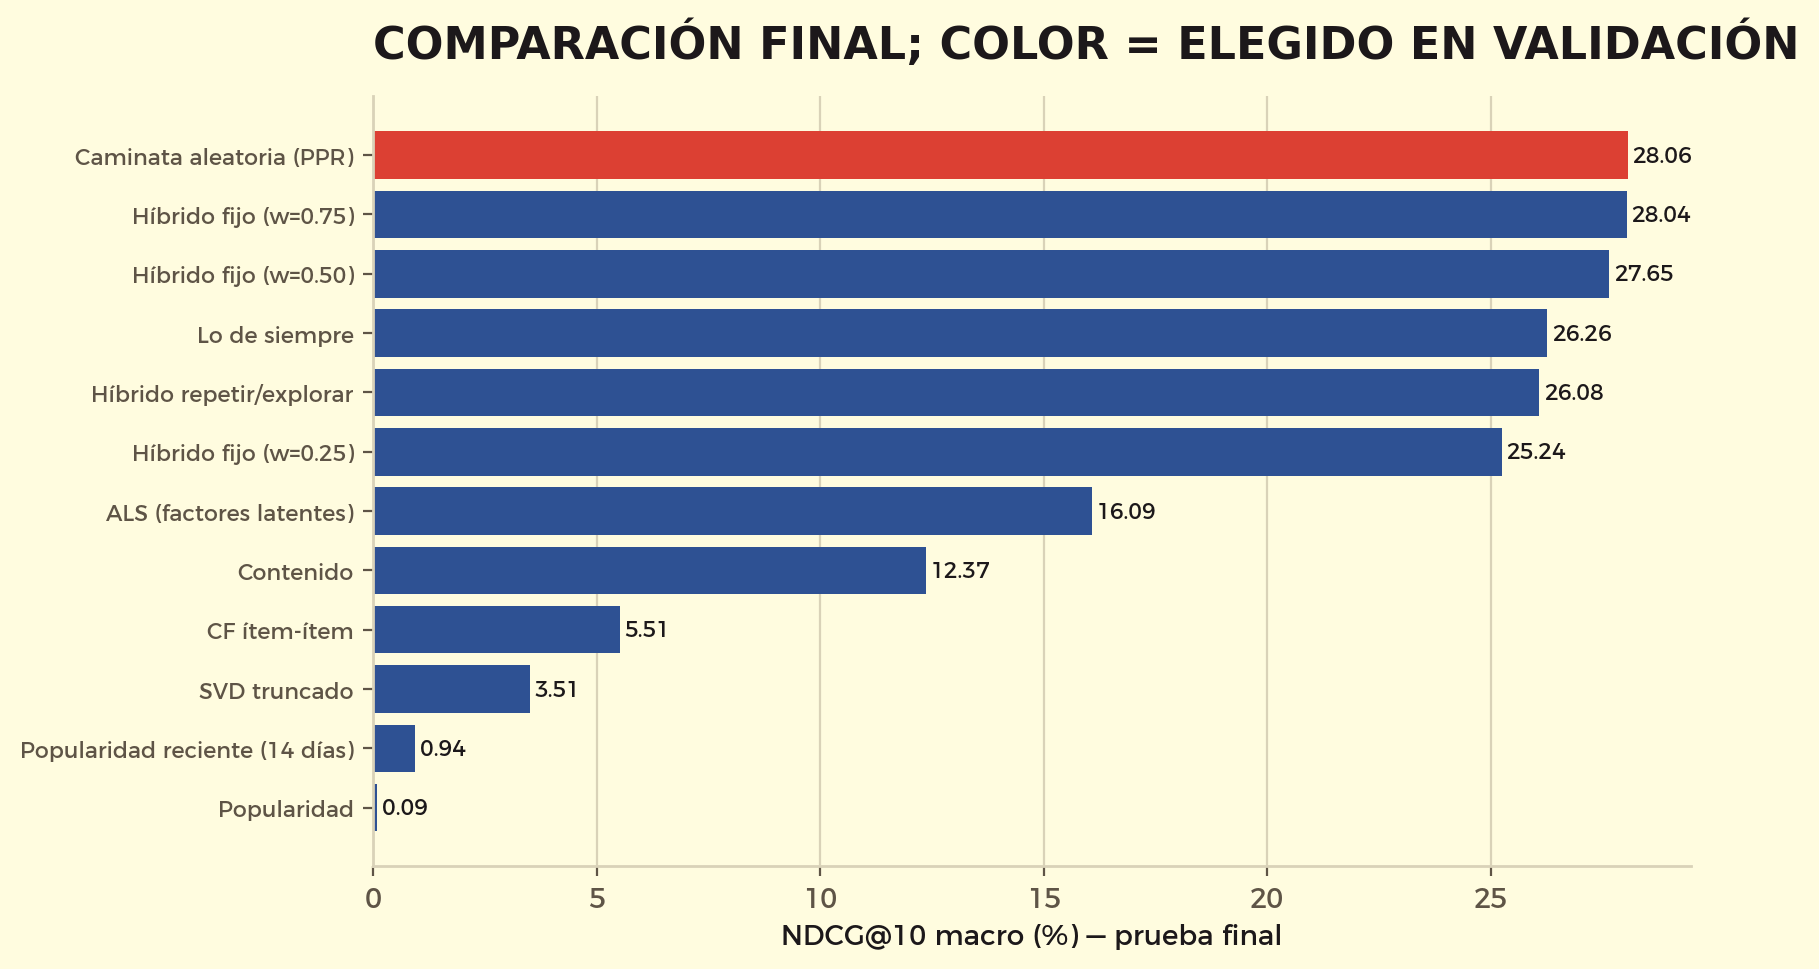

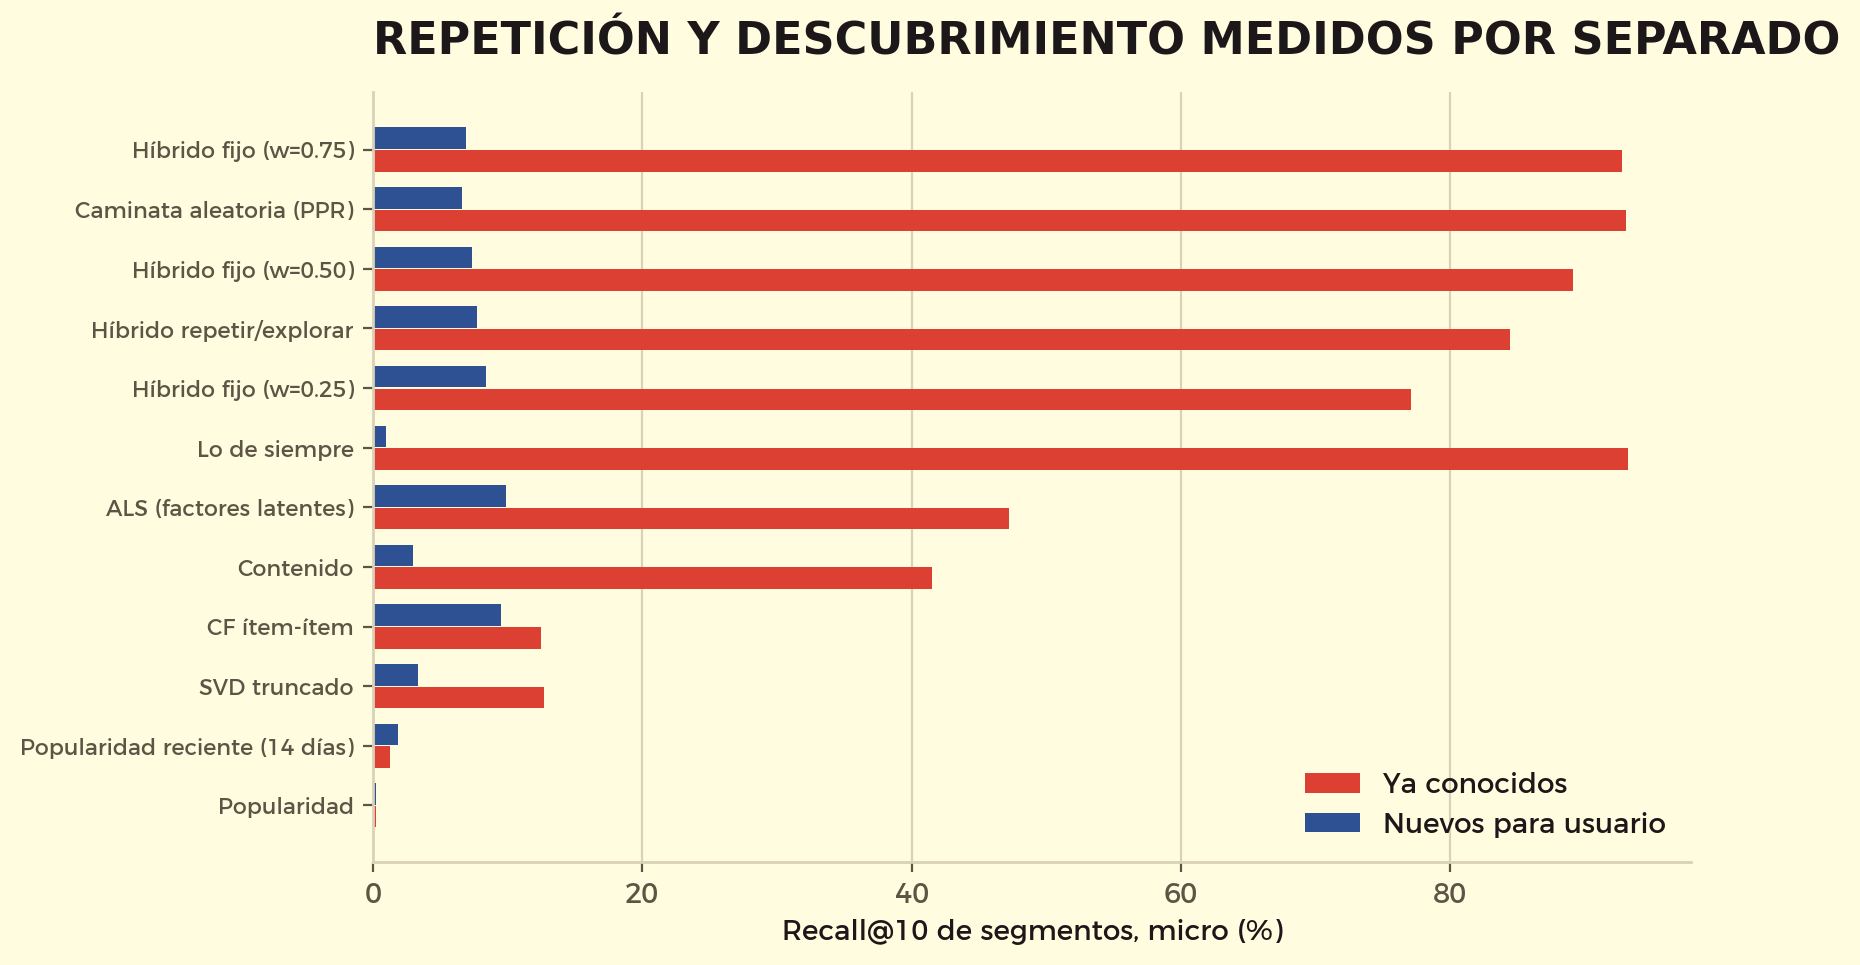

In [28]:
ganador = R['modelo_seleccionado_validacion']
selected_row = tabla.loc[tabla.modelo==ganador].iloc[0]
ndcg_ganador = float(selected_row['ndcg@10'])
base_pop = float(tabla.loc[tabla.modelo.str.startswith('Popularidad'),'ndcg@10'].max())
base_siempre = float(tabla.loc[tabla.modelo=='Lo de siempre','ndcg@10'].iloc[0])
R['modelo_ganador'],R['ndcg_ganador'] = ganador,ndcg_ganador
R['ndcg_popularidad'],R['ndcg_lo_de_siempre'] = base_pop,base_siempre
R['mejora_sobre_popularidad'] = ndcg_ganador/base_pop if base_pop>0 else None
R['mejora_sobre_lo_de_siempre'] = (ndcg_ganador/base_siempre-1)*100 if base_siempre>0 else None
print(f'Seleccionado por validación: {ganador}; NDCG test={ndcg_ganador:.3f}%')
print('Comparaciones pareadas en test:',R['incertidumbre']['comparaciones'])

fig,ax = plt.subplots(figsize=(8.5,5.0))
t = tabla.sort_values('ndcg@10')
ax.barh(range(len(t)),t['ndcg@10'],color=[JITOMATE if m==ganador else COBALTO for m in t.modelo])
for i,value in enumerate(t['ndcg@10']): ax.text(value+.1,i,f'{value:.2f}',va='center',fontsize=8)
ax.set_yticks(range(len(t)));ax.set_yticklabels(t.modelo,fontsize=8)
ax.set_xlabel('NDCG@10 macro (%) — prueba final')
titulo_ax(ax,'Comparación final; color = elegido en validación')
ax.grid(axis='x');ax.set_axisbelow(True)
guardar(fig,'04_modelos');plt.show()

fig,ax = plt.subplots(figsize=(8.5,5.0))
t2 = tabla.sort_values('recall@10');y = np.arange(len(t2))
ax.barh(y-.19,t2['recall repetidos'],height=.36,color=JITOMATE,label='Ya conocidos')
ax.barh(y+.19,t2['recall nuevos'],height=.36,color=COBALTO,label='Nuevos para usuario')
ax.set_yticks(y);ax.set_yticklabels(t2.modelo,fontsize=8)
ax.set_xlabel('Recall@10 de segmentos, micro (%)');ax.legend()
titulo_ax(ax,'Repetición y descubrimiento medidos por separado')
ax.grid(axis='x');ax.set_axisbelow(True)
guardar(fig,'07_repetir_vs_nuevos');plt.show()


## 9. Poca historia, catálogo nuevo y usuarios sin historial

Los restaurantes de **cero pedidos previos** se separan de los de **1–50**;
el número de pedidos mide actividad en esta muestra, no tamaño del negocio.
Se usa el mismo top diez final de cada modelo, sin favorecer al segmento.
El recall es micro y conserva objetivos fuera de la máscara territorial.
Nuevos para el usuario se evalúan aparte de nuevos para el sistema.
Para usuarios sin historial se mide un fallback de popularidad reciente global;
no hay dirección previa y no se observa el pedido futuro para inventarla.


Usuarios sin historial: {'protocolo': 'fallback global reciente; sin ubicación histórica y sin usar ubicación target', 'n_disponibles': 36766, 'n_evaluados': 20000, 'auditoria': {'usuarios_disponibles': 36766, 'usuarios_evaluados': 20000, 'relevantes_total': 23035, 'relevantes_en_catalogo_pct': 100.0, 'relevantes_geograficamente_elegibles_pct': 100.0, 'usuarios_sin_zona': 20000, 'usuarios_con_menos_de_10_candidatos': 0, 'candidatos_media': 7411.0}, 'metricas': {'modelo': 'Popularidad reciente (fallback sin historial)', 'precision@10': 0.093, 'recall@10': 0.8395833333333333, 'ndcg@10': 0.4052042847682894, 'recall repetidos': 0.0, 'recall nuevos': 0.8074668981983937, 'cobertura': 0.13493455673998112, 'segundos': 0.6907088756561279}}
→ figs/05_arranque_frio.png


<ipython-input-29-b626cbd51348>:48: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  guardar(fig,'05_arranque_frio');plt.show()


,segmento,modelo,relevantes,aciertos,usuarios_con_objetivo,recall_micro_pct
0,0 pedidos previos,Popularidad,317,0,311,0.000
1,1–50 pedidos previos,Popularidad,1225,0,1156,0.000
2,nuevos para usuario,Popularidad,21894,54,15411,0.247
3,0 pedidos previos,Popularidad reciente (14 días),317,0,311,0.000
4,1–50 pedidos previos,Popularidad reciente (14 días),1225,0,1156,0.000
5,nuevos para usuario,Popularidad reciente (14 días),21894,400,15411,1.827
6,0 pedidos previos,Lo de siempre,317,0,311,0.000
7,1–50 pedidos previos,Lo de siempre,1225,159,1156,12.980
8,nuevos para usuario,Lo de siempre,21894,218,15411,0.996
9,0 pedidos previos,Contenido,317,12,311,3.785


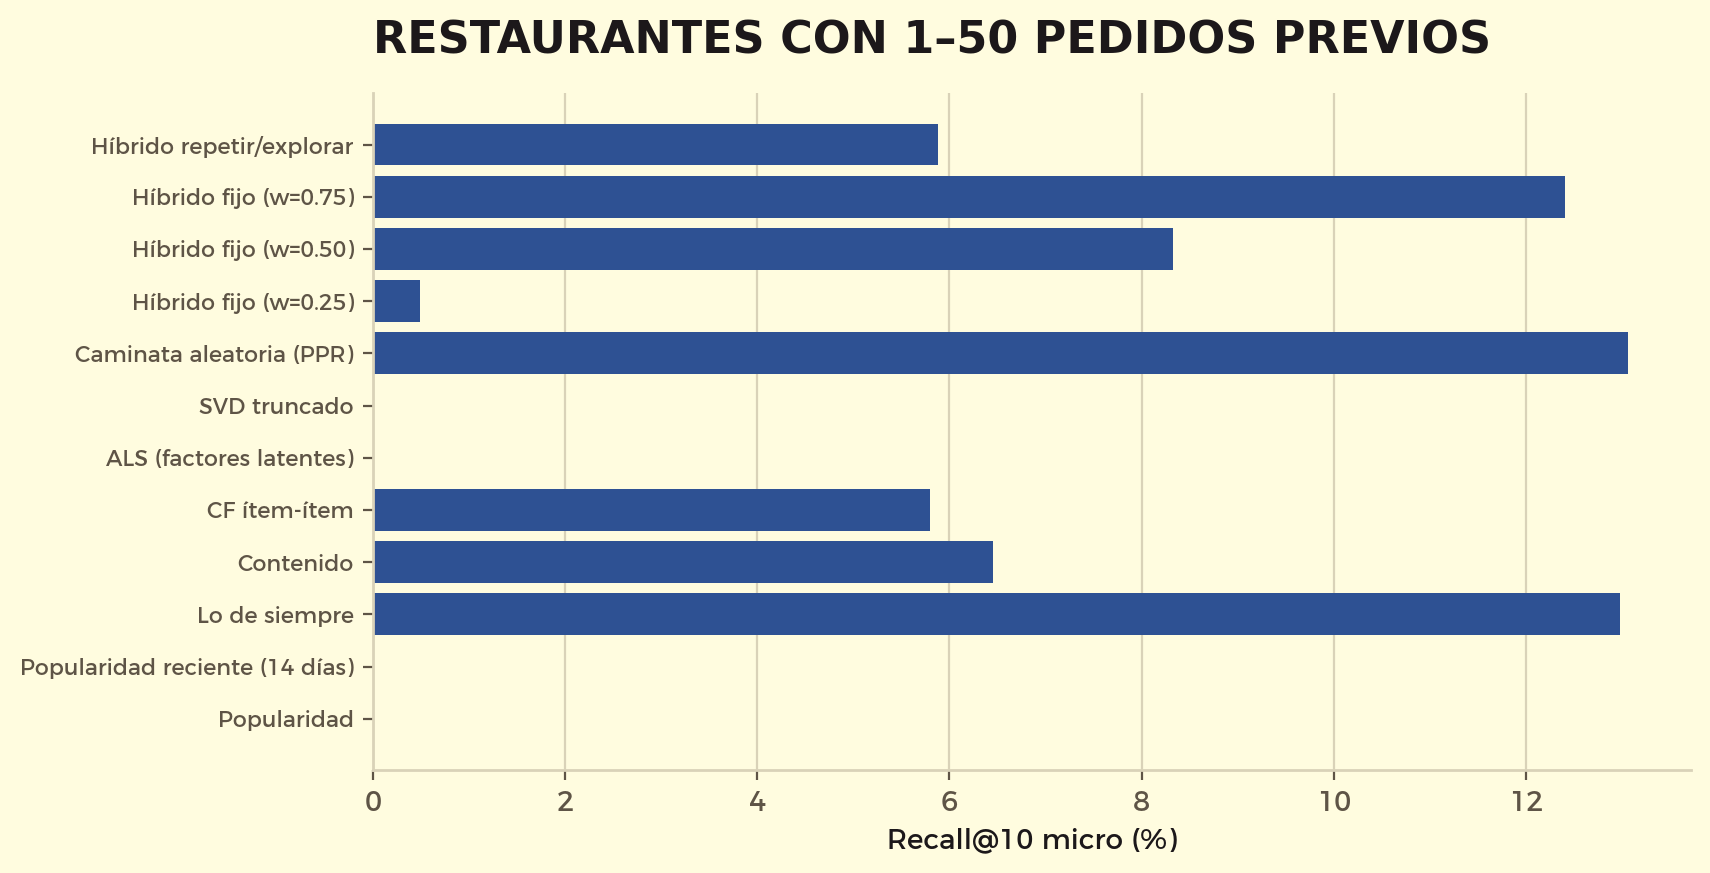

In [29]:
UMBRAL_PEQUENO = 50
groups = {'0 pedidos previos':set(np.flatnonzero(pop_scores==0)),
          '1–50 pedidos previos':set(np.flatnonzero((pop_scores>=1)&(pop_scores<=50)))}
segment_records = []
for name,rankings in ctx_test['rankings'].items():
    for segment,members in groups.items():
        hit,total,users_with_target = 0,0,0
        for i,rec in enumerate(rankings):
            objective = ctx_test['rel'][i] & members
            total += len(objective);users_with_target += bool(objective)
            hit += len(set(rec.tolist()) & objective)
        segment_records.append(dict(segmento=segment,modelo=name,relevantes=total,
            aciertos=hit,usuarios_con_objetivo=users_with_target,
            recall_micro_pct=100*hit/total if total else None))
    frame = ctx_test['metrics'][name]
    segment_records.append(dict(segmento='nuevos para usuario',modelo=name,
        relevantes=int(frame.nuevos.sum()),aciertos=int(frame.aciertos_nuevos.sum()),
        usuarios_con_objetivo=int((frame.nuevos>0).sum()),
        recall_micro_pct=100*frame.aciertos_nuevos.sum()/max(int(frame.nuevos.sum()),1)))
R['segmentos_restaurantes'] = segment_records
R['umbral_pequeno'] = UMBRAL_PEQUENO
R['n_vendors_pequenos'] = len(groups['1–50 pedidos previos'])
R['pct_vendors_pequenos'] = 100*R['n_vendors_pequenos']/len(vendor_idx)
R['n_vendors_sin_historial'] = len(groups['0 pedidos previos'])
frio = {x['modelo']:x['recall_micro_pct'] for x in segment_records if x['segmento']=='1–50 pedidos previos'}
R['arranque_frio'] = frio
valid_frio = {name:value for name,value in frio.items() if value is not None}
R['mejor_arranque_frio'] = max(valid_frio,key=valid_frio.get) if valid_frio else None
R['arranque_frio_interpretacion'] = 'baja actividad 1–50; comparación descriptiva; no tamaño real de negocio'

cold_metrics = None
if len(ctx_cold['users']):
    cold_metrics = evalua('Popularidad reciente (fallback sin historial)',
        lambda idx:np.broadcast_to(pop_rec,(len(idx),len(vendor_idx))),ctx_cold)
R['usuarios_nuevos'] = dict(protocolo='fallback global reciente; sin ubicación histórica y sin usar ubicación target',
    n_disponibles=ctx_cold['audit']['usuarios_disponibles'],n_evaluados=len(ctx_cold['users']),
    auditoria=ctx_cold['audit'],metricas=cold_metrics)
display(pd.DataFrame(segment_records).round(3))
print('Usuarios sin historial:',R['usuarios_nuevos'])

fig,ax = plt.subplots(figsize=(8.5,4.4))
names = list(valid_frio);values = list(valid_frio.values())
ax.barh(range(len(names)),values,color=COBALTO)
ax.set_yticks(range(len(names)));ax.set_yticklabels(names,fontsize=8)
ax.set_xlabel('Recall@10 micro (%)')
titulo_ax(ax,'Restaurantes con 1–50 pedidos previos')
ax.grid(axis='x');ax.set_axisbelow(True)
guardar(fig,'05_arranque_frio');plt.show()


## 10. Exploración visual de factores ALS

t-SNE es una proyección exploratoria de los restaurantes más pedidos: sus
ejes y las distancias entre grupos no prueban calidad de recomendación ni
agrupación por cocina. La evaluación temporal anterior mide el desempeño.


→ figs/06_mapa_tsne.png


<ipython-input-30-6691808e6c79>:15: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  guardar(fig,'06_mapa_tsne');plt.show()


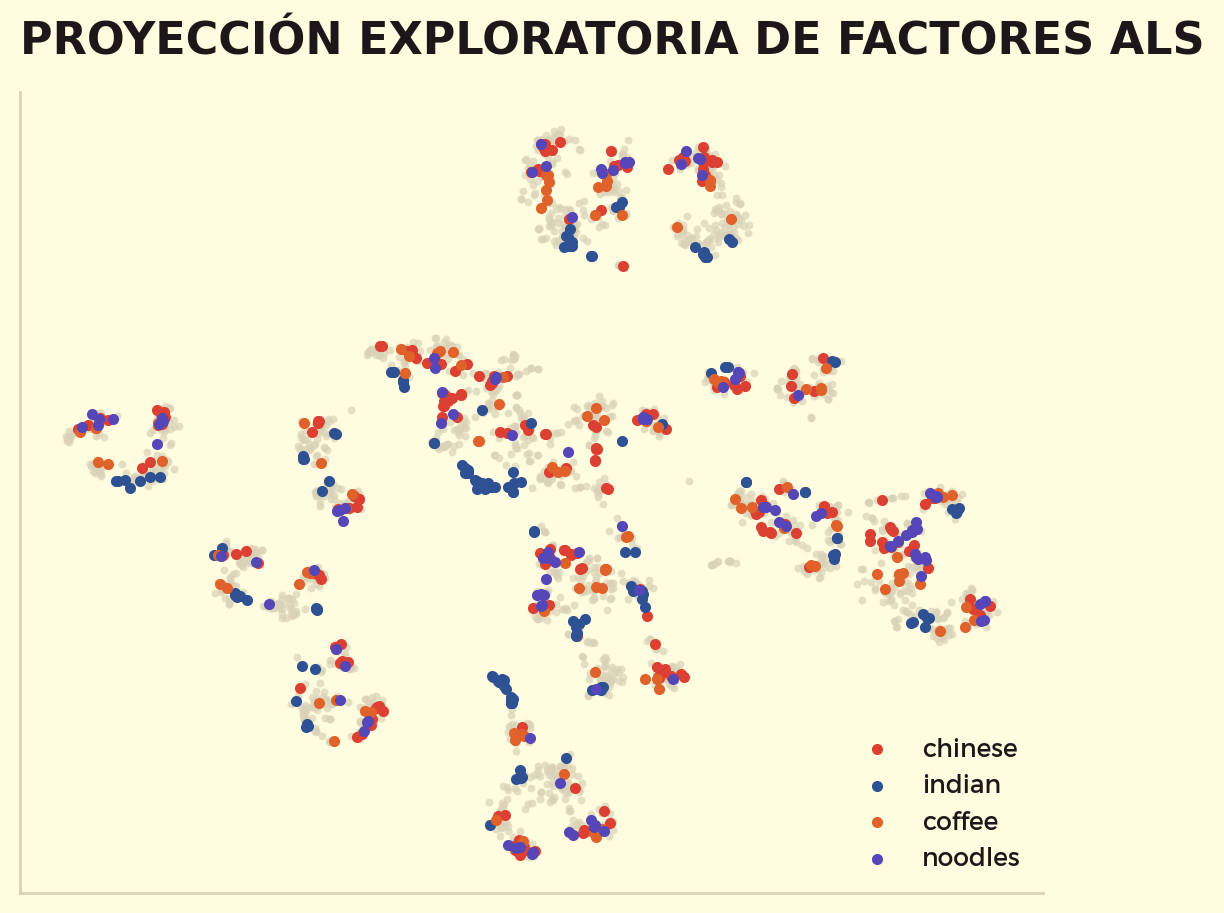

In [30]:
from sklearn.manifold import TSNE
n_mapa = min(800 if SMOKE else 2500,len(vendor_idx))
candidatos_mapa = np.argsort(-pop_scores,kind='stable')[:n_mapa]
with threadpool_limits(limits=1,user_api='blas'):
    emb = TSNE(n_components=2,perplexity=min(30,n_mapa-1),init='pca',random_state=SEED,
               max_iter=500 if SMOKE else 1000).fit_transform(V[candidatos_mapa])
coc_top = pd.Series(cocina_v[candidatos_mapa]).value_counts().head(4).index.tolist()
fig,ax = plt.subplots(figsize=(6.6,5.2))
ax.scatter(emb[:,0],emb[:,1],s=8,color=HAIRLINE,alpha=.7,linewidths=0)
for color,cuisine in zip(SERIE,coc_top):
    mask = cocina_v[candidatos_mapa]==cuisine
    ax.scatter(emb[mask,0],emb[mask,1],s=16,color=color,label=cuisine,linewidths=0)
ax.set_xticks([]);ax.set_yticks([]);ax.legend(loc='lower right',fontsize=9)
titulo_ax(ax,'Proyección exploratoria de factores ALS')
guardar(fig,'06_mapa_tsne');plt.show()


## 11. Resultados y trazabilidad

Se exportan tablas de validación y test, métricas individuales por usuario,
segmentos, calibración y diferencias con incertidumbre. Las cifras previas
se conservan en el respaldo del proyecto y no se mezclan con este protocolo.


In [31]:
import hashlib
import platform
from importlib.metadata import version
from zoneinfo import ZoneInfo
R['generado'] = pd.Timestamp.now(tz='America/Mexico_City').strftime('%Y-%m-%d %H:%M %Z')
R['ejecucion'] = dict(ciudad=CITY,semilla=SEED,smoke=SMOKE,python=platform.python_version(),
    plataforma=platform.platform(),zona_horaria=str(ZoneInfo('America/Mexico_City')),
    versiones={name:version(name) for name in ['numpy','pandas','scipy','scikit-learn','implicit','mlxtend','networkx']},
    configuracion=dict(TOP_K=TOP_K,N_EVAL_USERS=N_EVAL_USERS,CF_VECINOS=CF_VECINOS,
                      ALS_FACTORES=FACTORES,PPR_ALPHA=ALFA,PPR_TOL=PPR_TOL,PPR_MAX_ITER=PPR_MAX_ITER,
                      CORTE_VALIDACION=CORTE_VALIDACION,UMBRAL_PEQUENO=UMBRAL_PEQUENO))
_config_bytes = json.dumps(R['ejecucion']['configuracion'],sort_keys=True).encode()
R['ejecucion']['sha256_configuracion'] = hashlib.sha256(_config_bytes).hexdigest()
def _json_scalar(value):
    if isinstance(value,np.generic): return value.item()
    raise TypeError(type(value).__name__)
with (OUT/'resultados.json').open('w',encoding='utf-8') as f:
    json.dump(R,f,ensure_ascii=False,indent=2,default=_json_scalar,allow_nan=False)
tabla.to_csv(OUT/'tabla_modelos.csv',index=False)
tabla_val.to_csv(OUT/'tabla_validacion.csv',index=False)
individual = []
for split,ctx in [('validacion',ctx_val),('test',ctx_test),('sin_historial',ctx_cold)]:
    for name,frame in ctx['metrics'].items():
        individual.append(frame.assign(split=split,modelo=name))
pd.concat(individual,ignore_index=True).to_csv(OUT/'metricas_por_usuario.csv',index=False)
pd.DataFrame(R['segmentos_restaurantes']).to_csv(OUT/'segmentos_restaurantes.csv',index=False)
pd.DataFrame(R['clasificador']['calibracion_bins']).to_csv(OUT/'calibracion.csv',index=False)
pd.DataFrame(R['incertidumbre']['comparaciones']).to_csv(OUT/'comparaciones_pareadas.csv',index=False)
print('Resultados:',(OUT/'resultados.json').resolve())
print('Modelo seleccionado en validación:',R['modelo_seleccionado_validacion'])
display(tabla.round(3))


Resultados: /Users/mikitl/Documents/Codex/2026-10-03/es/outputs/export/resultados.json
Modelo seleccionado en validación: Caminata aleatoria (PPR)


,modelo,precision@10,recall@10,ndcg@10,recall repetidos,recall nuevos,cobertura,segundos
0,Caminata aleatoria (PPR),5.726,35.128,28.063,93.064,6.595,84.941,24.074
1,Híbrido fijo (w=0.75),5.738,35.282,28.041,92.720,6.869,83.632,6.020
2,Híbrido fijo (w=0.50),5.596,34.690,27.652,89.121,7.340,79.409,5.996
3,Lo de siempre,5.119,30.834,26.262,93.175,0.996,84.145,0.769
4,Híbrido repetir/explorar,5.389,33.047,26.082,84.444,7.742,70.179,6.029
5,Híbrido fijo (w=0.25),5.064,31.977,25.243,77.053,8.409,60.855,6.068
6,ALS (factores latentes),3.618,23.722,16.086,47.234,9.852,37.255,3.172
7,Contenido,2.556,17.704,12.366,41.525,2.946,99.042,3.300
8,CF ítem-ítem,1.711,9.769,5.514,12.487,9.496,92.741,2.799
9,SVD truncado,1.051,6.044,3.506,12.682,3.371,12.373,0.946
